## Recurrence plots + RQA for extreme-event (tail) dynamics


- **Signal**: we use $x_t = |r_t|$ (absolute returns) or a simple volatility proxy derived from returns.
- **Goal**: interpret recurrence patterns as signatures of **intermittent / weakly chaotic dynamics** that generate fat tails and clustering.
- **Non-goal**: recurrence plots here are **not** used for forecasting or trading.


/var/folders/wh/gb2tttfn5fg797ygz0nbbgq80000gn/T/ipykernel_36905/877881563.py:29: FutureWarning:

YF.download() has changed argument auto_adjust default to True

[*********************100%***********************]  15 of 15 completed


Analyzing time series...
Processing AAPL...
Processing MSFT...
Processing TSLA...
Processing BTC-USD...
Processing GOOG...
Processing GC=F...
Processing JPM...
Processing HSBC...
Processing DOGE-USD...
Processing ETH-USD...
Processing NFLX...
Processing AMZN...
Processing AMD...
Processing SI=F...
Processing SPY...

CHAOS AND RISK ANALYSIS SUMMARY
  Ticker  Lyapunov    Hurst  RQA_DET  RQA_ENTR        Chaos_Class    GPD_xi
    AAPL  0.211489 0.574723 0.351071  1.376024 MODERATELY CHAOTIC  0.012334
    MSFT  0.207852 0.413552 0.359922  1.390734 MODERATELY CHAOTIC -0.009777
    TSLA  0.211331 0.522200 0.347829  1.291274     HIGHLY CHAOTIC  0.048448
 BTC-USD  0.217083 0.587760 0.352925  1.388847 MODERATELY CHAOTIC  0.137469
    GOOG  0.216401 0.427712 0.351929  1.372734 MODERATELY CHAOTIC  0.077332
    GC=F  0.218999 0.581687 0.347379  1.260816 MODERATELY CHAOTIC  0.035847
     JPM  0.210034 0.466189 0.355240  1.349152     HIGHLY CHAOTIC  0.105909
    HSBC  0.220123 0.553984 0.357258  1.3

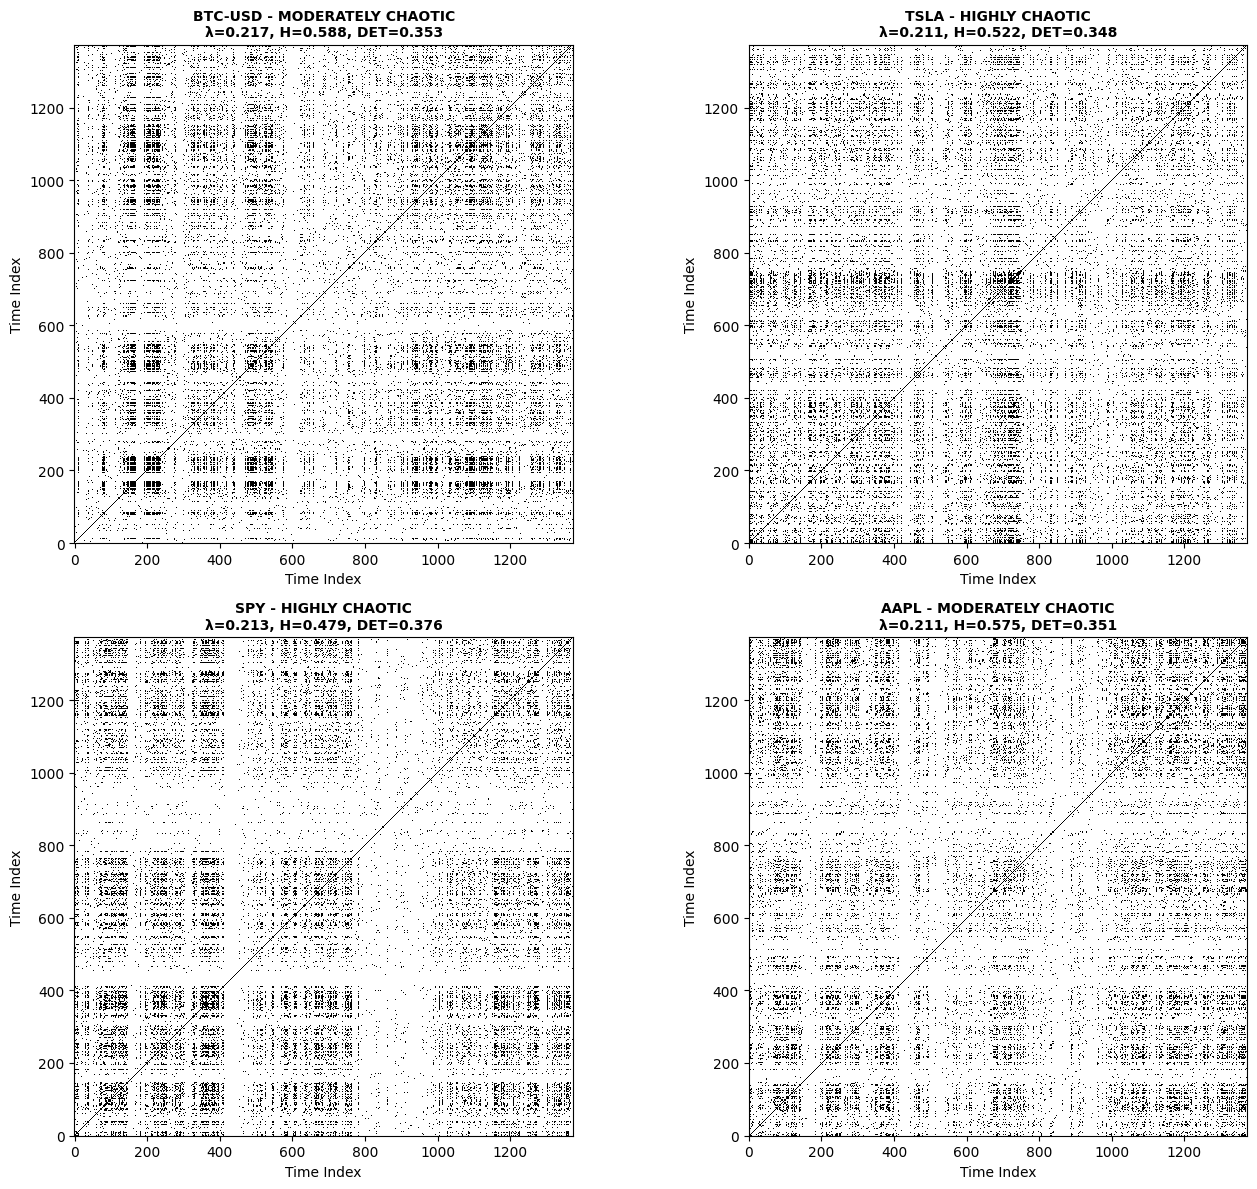

Chaos analysis plots saved as 'chaos_analysis.png'


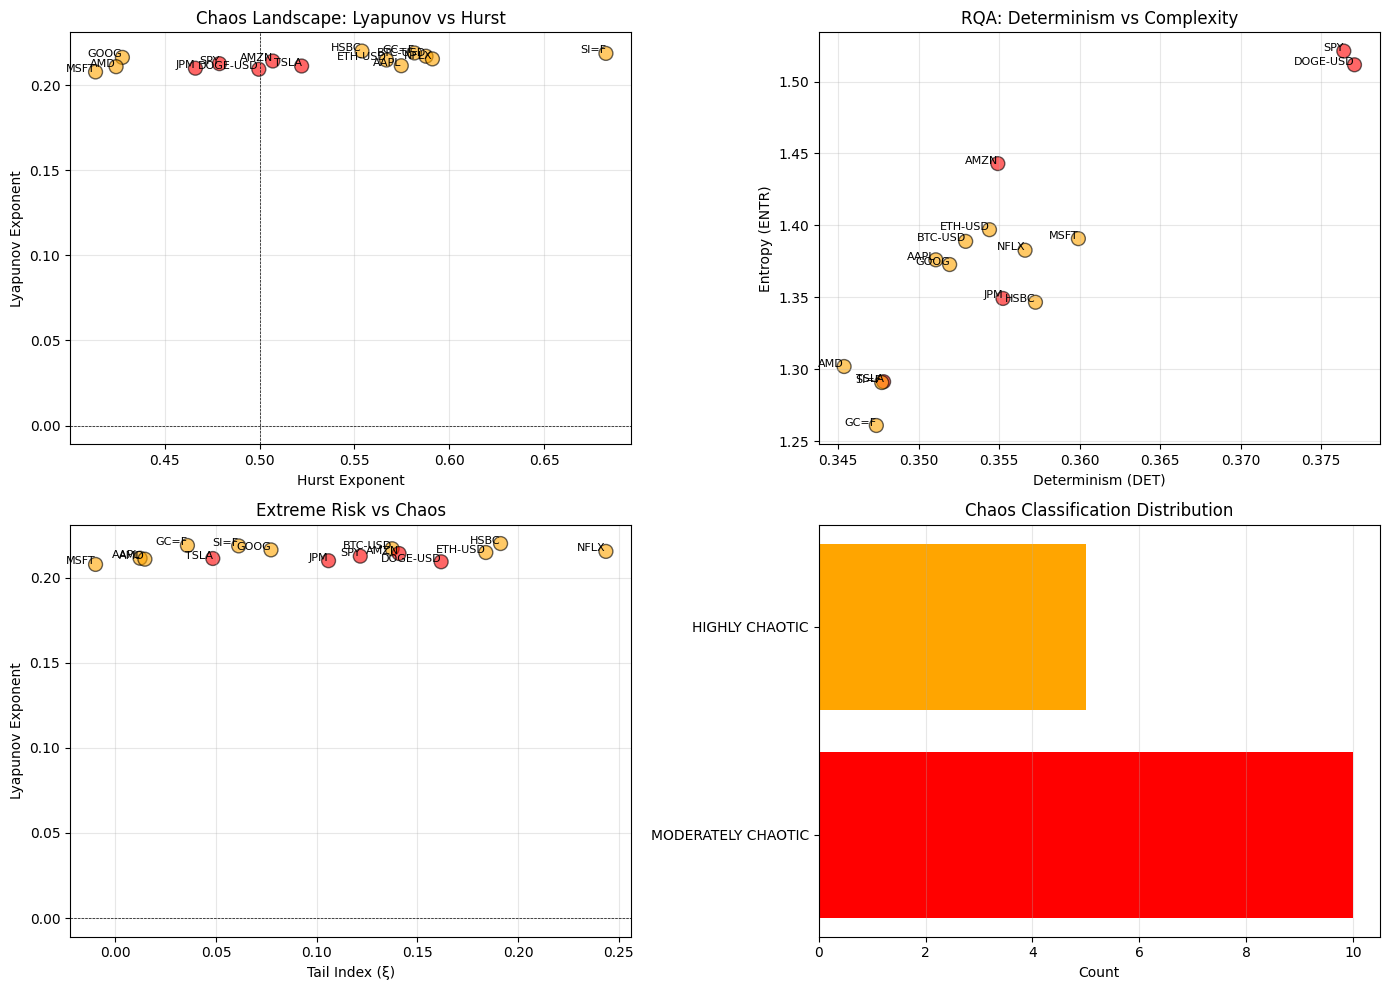


Analysis complete!


In [7]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.stats import norm, genpareto
from scipy.spatial.distance import pdist, squareform
from sklearn.neighbors import NearestNeighbors
from numpy.lib.stride_tricks import sliding_window_view

# -----------------------------
# Parameters
# -----------------------------
tickers = ["AAPL","MSFT","TSLA","BTC-USD","GOOG","GC=F","JPM","HSBC","DOGE-USD","ETH-USD","NFLX","AMZN","AMD","SI=F","SPY"]
start = "2018-01-01"
end   = "2025-01-01"
confidence_level = 0.95
min_exceedances = 20
np.random.seed(42)

# Recurrence plot parameters
embedding_dim = 3
time_delay = 1
recurrence_threshold_percentile = 10  # percent of max distance

# -----------------------------
# Download data
# -----------------------------
print("Downloading data...")
prices = yf.download(tickers, start=start, end=end)["Close"]

# -----------------------------
# Compute daily log-returns and losses
# -----------------------------
log_returns = np.log(prices / prices.shift(1)).dropna()
losses = -log_returns

# -----------------------------
# Recurrence Plot Functions
# -----------------------------
def embed_time_series(ts, m, tau):
    """Phase space reconstruction using time-delay embedding"""
    ts = np.array(ts)
    N = len(ts)
    M = N - (m - 1) * tau
    embedded = np.zeros((M, m))
    for i in range(m):
        embedded[:, i] = ts[i * tau:i * tau + M]
    return embedded

def recurrence_plot(ts, m=3, tau=1, threshold_percentile=10):
    """
    Compute recurrence plot matrix
    Returns: recurrence matrix, embedded trajectory, threshold used
    """
    # Embed time series
    embedded = embed_time_series(ts, m, tau)
    
    # Compute distance matrix
    dist_matrix = squareform(pdist(embedded, metric='euclidean'))
    
    # Set threshold as percentile of distances
    threshold = np.percentile(dist_matrix, threshold_percentile)
    
    # Create recurrence matrix
    R = (dist_matrix <= threshold).astype(int)
    
    return R, embedded, threshold

def recurrence_quantification_analysis(R):
    """
    Compute RQA measures to quantify recurrence plot structure
    """
    N = R.shape[0]
    
    # Recurrence Rate (RR): density of recurrence points
    RR = np.sum(R) / (N * N)
    
    # Determinism (DET): ratio of recurrence points in diagonal lines
    min_line_length = 2
    diag_lines = []
    for k in range(1, N):
        diag = np.diag(R, k)
        line_lengths = get_line_lengths(diag)
        diag_lines.extend([l for l in line_lengths if l >= min_line_length])
    
    if len(diag_lines) > 0:
        DET = sum(diag_lines) / np.sum(R)
        L = np.mean(diag_lines)  # Average diagonal line length
        L_max = max(diag_lines)   # Maximum diagonal line length
    else:
        DET = 0
        L = 0
        L_max = 0
    
    # Laminarity (LAM): ratio of recurrence points in vertical lines
    vert_lines = []
    for j in range(N):
        col = R[:, j]
        line_lengths = get_line_lengths(col)
        vert_lines.extend([l for l in line_lengths if l >= min_line_length])
    
    if len(vert_lines) > 0:
        LAM = sum(vert_lines) / np.sum(R)
        TT = np.mean(vert_lines)  # Trapping time
    else:
        LAM = 0
        TT = 0
    
    # Entropy: Shannon entropy of diagonal line length distribution
    if len(diag_lines) > 0:
        hist, _ = np.histogram(diag_lines, bins=range(min_line_length, max(diag_lines)+2))
        probs = hist / sum(hist)
        probs = probs[probs > 0]
        ENTR = -np.sum(probs * np.log(probs))
    else:
        ENTR = 0
    
    return {
        'RR': RR,
        'DET': DET,
        'L': L,
        'L_max': L_max,
        'LAM': LAM,
        'TT': TT,
        'ENTR': ENTR
    }

def get_line_lengths(binary_sequence):
    """Extract lengths of continuous sequences of 1s"""
    lengths = []
    current_length = 0
    for val in binary_sequence:
        if val == 1:
            current_length += 1
        else:
            if current_length > 0:
                lengths.append(current_length)
            current_length = 0
    if current_length > 0:
        lengths.append(current_length)
    return lengths

# -----------------------------
# Hurst exponent
# -----------------------------
def hurst_exponent(ts):
    ts = np.array(ts)
    N = len(ts)
    if N < 20:
        return np.nan
    max_k = N // 2
    rs = []
    lags = range(10, max_k, max(1, max_k//20))
    for lag in lags:
        y = ts[:lag]
        mean_y = np.mean(y)
        Z = np.cumsum(y - mean_y)
        R = np.max(Z) - np.min(Z)
        S = np.std(y)
        if S > 0:
            rs.append(R / S)
    if len(rs) < 2:
        return np.nan
    H = np.polyfit(np.log(lags[:len(rs)]), np.log(rs), 1)[0]
    return H

# -----------------------------
# Lyapunov exponent
# -----------------------------
def lyapunov_exponent(ts, m=2, tau=1, max_t=10, eps=1e-10):
    ts = np.array(ts)
    X = sliding_window_view(ts, window_shape=m)[::tau]
    N = len(X)
    if N <= m + max_t:
        return np.nan

    nbrs = NearestNeighbors(n_neighbors=2, algorithm='kd_tree').fit(X)
    distances, indices = nbrs.kneighbors(X)
    nearest_idx = indices[:, 1]
    dist0 = distances[:, 1]

    L = np.zeros(max_t)
    for i in range(max_t):
        di = []
        max_j = min(len(X)-i, len(nearest_idx))
        for j in range(max_j):
            ni = nearest_idx[j]
            if ni + i >= len(X):
                continue
            d = np.linalg.norm(X[j+i] - X[ni+i])
            di.append(np.log((d + eps)/(dist0[j] + eps)))
        if len(di) > 0:
            L[i] = np.mean(di)
    lam = np.polyfit(np.arange(max_t), L, 1)[0]
    return lam

# -----------------------------
# EVT function
# -----------------------------
def compute_evt(x, confidence_level=0.95, min_exceedances=20):
    for q in np.linspace(0.90, 0.98, 9):
        u = np.quantile(x, q)
        exceedances = x[x > u] - u
        if len(exceedances) >= min_exceedances:
            break
    else:
        return np.nan, np.nan, np.nan

    Nu, N = len(exceedances), len(x)
    xi, beta, _ = genpareto.fit(exceedances, floc=0)

    p_tail = 1 - confidence_level
    if xi < 1:
        VaR_evt = u + (beta / xi) * ((p_tail * N / Nu) ** (-xi) - 1)
        ES_evt  = (VaR_evt + beta - xi * u) / (1 - xi)
    else:
        VaR_evt, ES_evt = np.nan, np.nan

    return VaR_evt, ES_evt, xi

# -----------------------------
# Chaos Classifier
# -----------------------------
def classify_chaos(lam, H, DET, ENTR, L_max):
    """
    Classify chaotic nature based on multiple indicators
    """
    chaos_score = 0
    indicators = []
    
    # Lyapunov exponent
    if not np.isnan(lam):
        if lam > 0.1:
            chaos_score += 3
            indicators.append("Strong positive Lyapunov (highly chaotic)")
        elif lam > 0:
            chaos_score += 2
            indicators.append("Positive Lyapunov (chaotic)")
        else:
            indicators.append("Negative/zero Lyapunov (stable)")
    
    # Hurst exponent
    if not np.isnan(H):
        if 0.45 < H < 0.55:
            chaos_score += 2
            indicators.append("Hurst ≈ 0.5 (random walk/chaotic)")
        elif H > 0.5:
            indicators.append(f"Hurst = {H:.3f} (persistent/trending)")
        else:
            indicators.append(f"Hurst = {H:.3f} (mean-reverting)")
    
    # RQA Determinism
    if DET < 0.3:
        chaos_score += 1
        indicators.append("Low determinism (stochastic/chaotic)")
    elif DET > 0.7:
        indicators.append("High determinism (regular)")
    
    # RQA Entropy
    if ENTR > 2.0:
        chaos_score += 1
        indicators.append("High complexity (chaotic)")
    
    # Classification
    if chaos_score >= 5:
        classification = "HIGHLY CHAOTIC"
    elif chaos_score >= 3:
        classification = "MODERATELY CHAOTIC"
    elif chaos_score >= 1:
        classification = "WEAKLY CHAOTIC"
    else:
        classification = "PREDOMINANTLY STABLE"
    
    return classification, indicators

# -----------------------------
# Compute all measures
# -----------------------------
print("\nAnalyzing time series...")
results = []

for ticker in tickers:
    print(f"Processing {ticker}...")
    x = losses[ticker].dropna().values
    returns = log_returns[ticker].dropna().values
    
    mu, sigma = x.mean(), x.std()

    # Gaussian VaR/ES
    z = norm.ppf(confidence_level)
    VaR_gaussian = mu + sigma * z
    ES_gaussian  = mu + sigma * norm.pdf(z) / (1 - confidence_level)

    # EVT VaR/ES
    VaR_evt, ES_evt, xi = compute_evt(x, confidence_level, min_exceedances)

    # Hurst exponent
    H = hurst_exponent(returns)

    # Lyapunov exponent
    lam = lyapunov_exponent(returns)
    
    # Recurrence analysis
    R, embedded, threshold = recurrence_plot(returns, m=embedding_dim, 
                                            tau=time_delay, 
                                            threshold_percentile=recurrence_threshold_percentile)
    rqa = recurrence_quantification_analysis(R)
    
    # Classify chaos
    chaos_class, chaos_indicators = classify_chaos(lam, H, rqa['DET'], rqa['ENTR'], rqa['L_max'])

    results.append({
        "Ticker": ticker,
        "Gaussian_VaR": VaR_gaussian,
        "Gaussian_ES": ES_gaussian,
        "EVT_VaR": VaR_evt,
        "EVT_ES": ES_evt,
        "GPD_xi": xi,
        "Hurst": H,
        "Lyapunov": lam,
        "RQA_RR": rqa['RR'],
        "RQA_DET": rqa['DET'],
        "RQA_L": rqa['L'],
        "RQA_LAM": rqa['LAM'],
        "RQA_ENTR": rqa['ENTR'],
        "Chaos_Class": chaos_class,
        "Chaos_Indicators": "; ".join(chaos_indicators),
        "Recurrence_Matrix": R
    })

# -----------------------------
# Create summary
# -----------------------------
summary = pd.DataFrame(results)

# Enhanced risk comments
risk_comments = []
for i, row in summary.iterrows():
    xi = row['GPD_xi']
    
    if np.isnan(row['EVT_VaR']) or np.isnan(row['EVT_ES']):
        risk_comment = f"⚠️ {row['Chaos_Class']}: EVT undefined; "
    else:
        risk_comment = f"{row['Chaos_Class']}: EVT VaR={row['EVT_VaR']:.4f}, ES={row['EVT_ES']:.4f}; "
    
    if xi < 0:
        risk_comment += f"ξ={xi:.3f} (bounded tail); "
    elif 0 <= xi < 0.5:
        risk_comment += f"ξ={xi:.3f} (moderate fat tail); "
    elif 0.5 <= xi < 1:
        risk_comment += f"ξ={xi:.3f} (heavy tail, extreme losses possible); "
    else:
        risk_comment += f"ξ={xi:.3f} (extreme tail); "
    
    risk_comment += f"DET={row['RQA_DET']:.3f}, ENTR={row['RQA_ENTR']:.3f}"
    risk_comments.append(risk_comment)

summary['Risk_Summary'] = risk_comments

# Display results
pd.set_option('display.max_colwidth', None)
print("\n" + "="*120)
print("CHAOS AND RISK ANALYSIS SUMMARY")
print("="*120)
print(summary[['Ticker', 'Lyapunov', 'Hurst', 'RQA_DET', 'RQA_ENTR', 'Chaos_Class', 'GPD_xi']].to_string(index=False))
print("\n" + "="*120)
print("DETAILED RISK SUMMARIES")
print("="*120)
for i, row in summary.iterrows():
    print(f"\n{row['Ticker']}:")
    print(f"  {row['Risk_Summary']}")
    print(f"  Indicators: {row['Chaos_Indicators']}")

# -----------------------------
# Plot recurrence plots for selected tickers
# -----------------------------
print("\n\nGenerating recurrence plots...")
selected_tickers = ["BTC-USD", "TSLA", "SPY", "AAPL"]
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.flatten()

for idx, ticker in enumerate(selected_tickers):
    if ticker in summary['Ticker'].values:
        row = summary[summary['Ticker'] == ticker].iloc[0]
        R = row['Recurrence_Matrix']
        
        ax = axes[idx]
        im = ax.imshow(R, cmap='binary', origin='lower', interpolation='nearest')
        ax.set_title(f"{ticker} - {row['Chaos_Class']}\nλ={row['Lyapunov']:.3f}, H={row['Hurst']:.3f}, DET={row['RQA_DET']:.3f}", 
                    fontsize=10, fontweight='bold')
        ax.set_xlabel('Time Index')
        ax.set_ylabel('Time Index')
        ax.grid(False)

plt.tight_layout()
plt.savefig('recurrence_plots.png', dpi=300, bbox_inches='tight')
print("Recurrence plots saved as 'recurrence_plots.png'")
plt.show()

# -----------------------------
# Additional chaos metrics visualization
# -----------------------------
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Lyapunov vs Hurst
ax1 = axes[0, 0]
colors = ['red' if 'HIGHLY' in c else 'orange' if 'MODERATELY' in c else 'yellow' if 'WEAKLY' in c else 'green' 
          for c in summary['Chaos_Class']]
ax1.scatter(summary['Hurst'], summary['Lyapunov'], c=colors, s=100, alpha=0.6, edgecolors='black')
for i, txt in enumerate(summary['Ticker']):
    ax1.annotate(txt, (summary['Hurst'].iloc[i], summary['Lyapunov'].iloc[i]), 
                fontsize=8, ha='right')
ax1.axhline(0, color='black', linestyle='--', linewidth=0.5)
ax1.axvline(0.5, color='black', linestyle='--', linewidth=0.5)
ax1.set_xlabel('Hurst Exponent')
ax1.set_ylabel('Lyapunov Exponent')
ax1.set_title('Chaos Landscape: Lyapunov vs Hurst')
ax1.grid(True, alpha=0.3)

# RQA Determinism vs Entropy
ax2 = axes[0, 1]
ax2.scatter(summary['RQA_DET'], summary['RQA_ENTR'], c=colors, s=100, alpha=0.6, edgecolors='black')
for i, txt in enumerate(summary['Ticker']):
    ax2.annotate(txt, (summary['RQA_DET'].iloc[i], summary['RQA_ENTR'].iloc[i]), 
                fontsize=8, ha='right')
ax2.set_xlabel('Determinism (DET)')
ax2.set_ylabel('Entropy (ENTR)')
ax2.set_title('RQA: Determinism vs Complexity')
ax2.grid(True, alpha=0.3)

# GPD tail index vs Lyapunov
ax3 = axes[1, 0]
ax3.scatter(summary['GPD_xi'], summary['Lyapunov'], c=colors, s=100, alpha=0.6, edgecolors='black')
for i, txt in enumerate(summary['Ticker']):
    ax3.annotate(txt, (summary['GPD_xi'].iloc[i], summary['Lyapunov'].iloc[i]), 
                fontsize=8, ha='right')
ax3.axhline(0, color='black', linestyle='--', linewidth=0.5)
ax3.set_xlabel('Tail Index (ξ)')
ax3.set_ylabel('Lyapunov Exponent')
ax3.set_title('Extreme Risk vs Chaos')
ax3.grid(True, alpha=0.3)

# Chaos classification distribution
ax4 = axes[1, 1]
chaos_counts = summary['Chaos_Class'].value_counts()
ax4.barh(chaos_counts.index, chaos_counts.values, 
        color=['red', 'orange', 'yellow', 'green'][:len(chaos_counts)])
ax4.set_xlabel('Count')
ax4.set_title('Chaos Classification Distribution')
ax4.grid(True, alpha=0.3, axis='x')

plt.tight_layout()
plt.savefig('chaos_analysis.png', dpi=300, bbox_inches='tight')
print("Chaos analysis plots saved as 'chaos_analysis.png'")
plt.show()

print("\n" + "="*120)
print("Analysis complete!")
print("="*120)

/var/folders/wh/gb2tttfn5fg797ygz0nbbgq80000gn/T/ipykernel_36905/2635968969.py:33: FutureWarning:

YF.download() has changed argument auto_adjust default to True

[                       0%                       ]

[*********************100%***********************]  15 of 15 completed



Analyzing time series with chaos-conditioned risk...
Processing AAPL...
Processing MSFT...
Processing TSLA...
Processing BTC-USD...
Processing GOOG...
Processing GC=F...
Processing JPM...
Processing HSBC...
Processing DOGE-USD...
Processing ETH-USD...
Processing NFLX...
Processing AMZN...
Processing AMD...
Processing SI=F...
Processing SPY...

CHAOS-CONDITIONED RISK ANALYSIS
  Ticker  Gaussian_VaR  Chaos_VaR  EVT_VaR_Standard  EVT_VaR_Regime  Chaos_State_Z  Escape_Prob
    AAPL      0.029773   0.037180          0.019351        0.019351       0.718146          0.9
    MSFT      0.028189   0.035248          0.019782        0.019782       0.718033          0.9
    TSLA      0.061599   0.076341          0.041324        0.041324       0.711492          0.9
 BTC-USD      0.061965   0.077124          0.037846        0.037846       0.719895          0.9
    GOOG      0.030975   0.038643          0.020651        0.020651       0.718596          0.9
    GC=F      0.014922   0.018587          0.

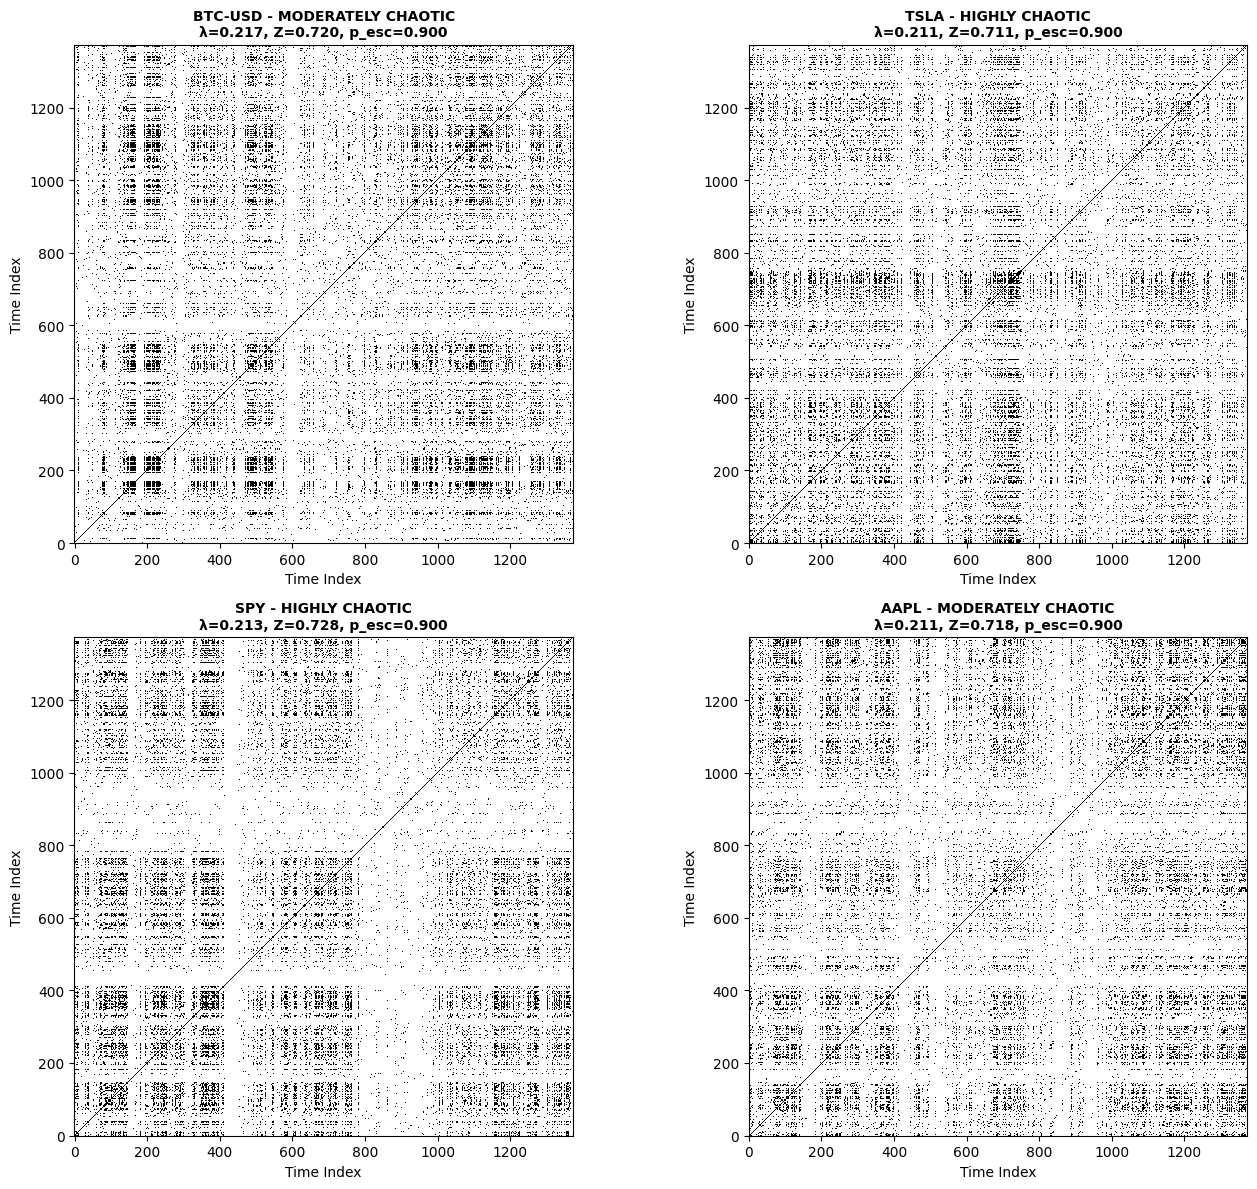

Model comparison saved as 'chaos_model_comparison.png'


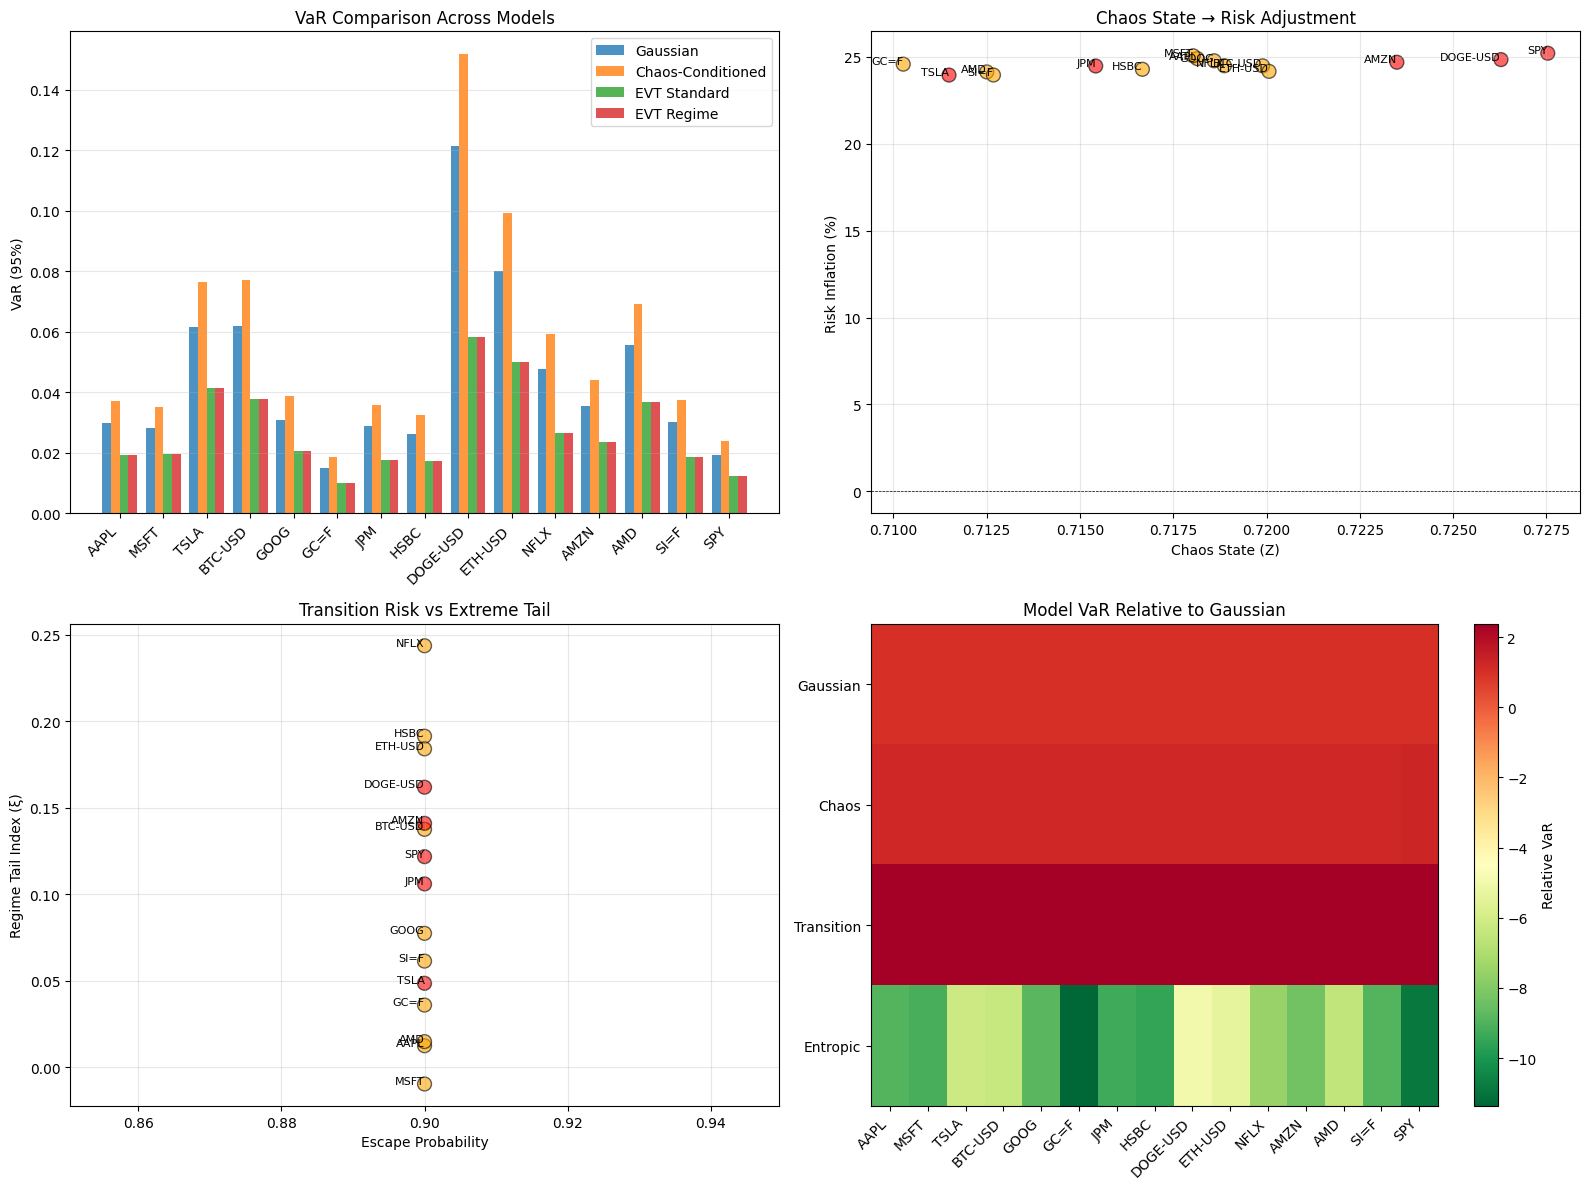


CHAOS-CONDITIONED PROBABILISTIC RISK FRAMEWORK COMPLETE

Key Innovations:
1. Chaos State Index (Z) modulates probability distribution of returns
2. Regime-Conditional EVT isolates structurally extreme states
3. Escape Probability captures transition risk from recurrence geometry
4. Entropic Risk Measure provides distribution-free risk quantification
5. All models maintain returns as primitive (stationary), chaos as probability shifter


In [8]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.stats import norm, genpareto, gaussian_kde
from scipy.spatial.distance import pdist, squareform
from sklearn.neighbors import NearestNeighbors
from numpy.lib.stride_tricks import sliding_window_view

# -----------------------------
# Parameters
# -----------------------------
tickers = ["AAPL","MSFT","TSLA","BTC-USD","GOOG","GC=F","JPM","HSBC","DOGE-USD","ETH-USD","NFLX","AMZN","AMD","SI=F","SPY"]
start = "2018-01-01"
end   = "2025-01-01"
confidence_level = 0.95
min_exceedances = 20
np.random.seed(42)

# Recurrence plot parameters
embedding_dim = 3
time_delay = 1
recurrence_threshold_percentile = 10

# Chaos modulation parameters
gamma = 0.3  # Volatility sensitivity to chaos
chaos_percentile = 0.75  # Threshold for high-chaos regime

# -----------------------------
# Download data
# -----------------------------
print("Downloading data...")
prices = yf.download(tickers, start=start, end=end)["Close"]

# -----------------------------
# Compute daily log-returns and losses
# -----------------------------
log_returns = np.log(prices / prices.shift(1)).dropna()
losses = -log_returns

# -----------------------------
# Recurrence Plot Functions
# -----------------------------
def embed_time_series(ts, m, tau):
    """Phase space reconstruction using time-delay embedding"""
    ts = np.array(ts)
    N = len(ts)
    M = N - (m - 1) * tau
    embedded = np.zeros((M, m))
    for i in range(m):
        embedded[:, i] = ts[i * tau:i * tau + M]
    return embedded

def recurrence_plot(ts, m=3, tau=1, threshold_percentile=10):
    """Compute recurrence plot matrix"""
    embedded = embed_time_series(ts, m, tau)
    dist_matrix = squareform(pdist(embedded, metric='euclidean'))
    threshold = np.percentile(dist_matrix, threshold_percentile)
    R = (dist_matrix <= threshold).astype(int)
    return R, embedded, threshold

def recurrence_quantification_analysis(R):
    """Compute RQA measures to quantify recurrence plot structure"""
    N = R.shape[0]
    RR = np.sum(R) / (N * N)
    
    min_line_length = 2
    diag_lines = []
    for k in range(1, N):
        diag = np.diag(R, k)
        line_lengths = get_line_lengths(diag)
        diag_lines.extend([l for l in line_lengths if l >= min_line_length])
    
    if len(diag_lines) > 0:
        DET = sum(diag_lines) / np.sum(R)
        L = np.mean(diag_lines)
        L_max = max(diag_lines)
    else:
        DET = 0
        L = 0
        L_max = 0
    
    vert_lines = []
    for j in range(N):
        col = R[:, j]
        line_lengths = get_line_lengths(col)
        vert_lines.extend([l for l in line_lengths if l >= min_line_length])
    
    if len(vert_lines) > 0:
        LAM = sum(vert_lines) / np.sum(R)
        TT = np.mean(vert_lines)
    else:
        LAM = 0
        TT = 0
    
    if len(diag_lines) > 0:
        hist, _ = np.histogram(diag_lines, bins=range(min_line_length, max(diag_lines)+2))
        probs = hist / sum(hist)
        probs = probs[probs > 0]
        ENTR = -np.sum(probs * np.log(probs))
    else:
        ENTR = 0
    
    return {
        'RR': RR, 'DET': DET, 'L': L, 'L_max': L_max,
        'LAM': LAM, 'TT': TT, 'ENTR': ENTR
    }

def get_line_lengths(binary_sequence):
    """Extract lengths of continuous sequences of 1s"""
    lengths = []
    current_length = 0
    for val in binary_sequence:
        if val == 1:
            current_length += 1
        else:
            if current_length > 0:
                lengths.append(current_length)
            current_length = 0
    if current_length > 0:
        lengths.append(current_length)
    return lengths

# -----------------------------
# Hurst exponent
# -----------------------------
def hurst_exponent(ts):
    ts = np.array(ts)
    N = len(ts)
    if N < 20:
        return np.nan
    max_k = N // 2
    rs = []
    lags = range(10, max_k, max(1, max_k//20))
    for lag in lags:
        y = ts[:lag]
        mean_y = np.mean(y)
        Z = np.cumsum(y - mean_y)
        R = np.max(Z) - np.min(Z)
        S = np.std(y)
        if S > 0:
            rs.append(R / S)
    if len(rs) < 2:
        return np.nan
    H = np.polyfit(np.log(lags[:len(rs)]), np.log(rs), 1)[0]
    return H

# -----------------------------
# Lyapunov exponent
# -----------------------------
def lyapunov_exponent(ts, m=2, tau=1, max_t=10, eps=1e-10):
    ts = np.array(ts)
    X = sliding_window_view(ts, window_shape=m)[::tau]
    N = len(X)
    if N <= m + max_t:
        return np.nan

    nbrs = NearestNeighbors(n_neighbors=2, algorithm='kd_tree').fit(X)
    distances, indices = nbrs.kneighbors(X)
    nearest_idx = indices[:, 1]
    dist0 = distances[:, 1]

    L = np.zeros(max_t)
    for i in range(max_t):
        di = []
        max_j = min(len(X)-i, len(nearest_idx))
        for j in range(max_j):
            ni = nearest_idx[j]
            if ni + i >= len(X):
                continue
            d = np.linalg.norm(X[j+i] - X[ni+i])
            di.append(np.log((d + eps)/(dist0[j] + eps)))
        if len(di) > 0:
            L[i] = np.mean(di)
    lam = np.polyfit(np.arange(max_t), L, 1)[0]
    return lam

# -----------------------------
# NEW: Chaos State Index
# -----------------------------
def compute_chaos_state(lam, DET, ENTR, RR):
    """
    Compute latent chaos state Z_t
    High Z → unstable/chaotic regime
    Low Z → stable regime
    """
    Z = (
        np.maximum(lam, 0) * 2.0 +  # Weight positive Lyapunov heavily
        (1 - DET) +                  # Low determinism = high chaos
        ENTR +                       # High entropy = high chaos
        RR                           # Recurrence rate contribution
    )
    return Z

# -----------------------------
# NEW: Chaos-Conditioned Volatility
# -----------------------------
def chaos_modulated_volatility(sigma_base, Z, gamma=0.3):
    """
    σ(Z_t) = σ₀ · exp(γ · Z_t)
    Volatility inflates in chaotic regimes
    """
    return sigma_base * np.exp(gamma * Z)

# -----------------------------
# NEW: Regime-Conditional EVT
# -----------------------------
def compute_regime_evt(x, Z, confidence_level=0.95, min_exceedances=20, chaos_threshold=0.75):
    """
    Fit EVT only on high-chaos regime losses
    This isolates structurally extreme states
    """
    # Select high-chaos regime
    Z_threshold = np.quantile(Z, chaos_threshold)
    high_chaos_mask = Z > Z_threshold
    
    if np.sum(high_chaos_mask) < min_exceedances * 2:
        # Fall back to standard EVT if insufficient data
        return compute_evt(x, confidence_level, min_exceedances)
    
    x_chaos = x[high_chaos_mask]
    return compute_evt(x_chaos, confidence_level, min_exceedances)

# -----------------------------
# Standard EVT function
# -----------------------------
def compute_evt(x, confidence_level=0.95, min_exceedances=20):
    for q in np.linspace(0.90, 0.98, 9):
        u = np.quantile(x, q)
        exceedances = x[x > u] - u
        if len(exceedances) >= min_exceedances:
            break
    else:
        return np.nan, np.nan, np.nan

    Nu, N = len(exceedances), len(x)
    xi, beta, _ = genpareto.fit(exceedances, floc=0)

    p_tail = 1 - confidence_level
    if xi < 1:
        VaR_evt = u + (beta / xi) * ((p_tail * N / Nu) ** (-xi) - 1)
        ES_evt  = (VaR_evt + beta - xi * u) / (1 - xi)
    else:
        VaR_evt, ES_evt = np.nan, np.nan

    return VaR_evt, ES_evt, xi

# -----------------------------
# NEW: Escape Probability from Recurrence
# -----------------------------
def compute_escape_probability(R):
    """
    p_escape(t) = P(X_{t+1} ∉ recurrence core)
    Measures likelihood of regime transition
    """
    if R.shape[0] == 0:
        return 0.0
    # Average non-recurrence per time point
    escape_probs = 1 - R.mean(axis=1)
    return escape_probs.mean()

# -----------------------------
# NEW: Entropic Risk Measure
# -----------------------------
def compute_entropic_risk(returns, embedded):
    """
    ρ_t = -log p(X_t) using KDE
    Higher values = lower probability states = higher risk
    """
    try:
        kde = gaussian_kde(embedded.T)
        log_probs = kde.logpdf(embedded.T)
        entropy_risk = -log_probs.mean()
        return entropy_risk
    except:
        return 0.0

# -----------------------------
# Chaos Classifier
# -----------------------------
def classify_chaos(lam, H, DET, ENTR, L_max):
    """Classify chaotic nature based on multiple indicators"""
    chaos_score = 0
    indicators = []
    
    if not np.isnan(lam):
        if lam > 0.1:
            chaos_score += 3
            indicators.append("Strong positive Lyapunov (highly chaotic)")
        elif lam > 0:
            chaos_score += 2
            indicators.append("Positive Lyapunov (chaotic)")
        else:
            indicators.append("Negative/zero Lyapunov (stable)")
    
    if not np.isnan(H):
        if 0.45 < H < 0.55:
            chaos_score += 2
            indicators.append("Hurst ≈ 0.5 (random walk/chaotic)")
        elif H > 0.5:
            indicators.append(f"Hurst = {H:.3f} (persistent/trending)")
        else:
            indicators.append(f"Hurst = {H:.3f} (mean-reverting)")
    
    if DET < 0.3:
        chaos_score += 1
        indicators.append("Low determinism (stochastic/chaotic)")
    elif DET > 0.7:
        indicators.append("High determinism (regular)")
    
    if ENTR > 2.0:
        chaos_score += 1
        indicators.append("High complexity (chaotic)")
    
    if chaos_score >= 5:
        classification = "HIGHLY CHAOTIC"
    elif chaos_score >= 3:
        classification = "MODERATELY CHAOTIC"
    elif chaos_score >= 1:
        classification = "WEAKLY CHAOTIC"
    else:
        classification = "PREDOMINANTLY STABLE"
    
    return classification, indicators

# -----------------------------
# Main Analysis
# -----------------------------
print("\nAnalyzing time series with chaos-conditioned risk...")
results = []

for ticker in tickers:
    print(f"Processing {ticker}...")
    x = losses[ticker].dropna().values
    returns = log_returns[ticker].dropna().values
    
    mu, sigma = x.mean(), x.std()

    # === Standard Gaussian VaR/ES ===
    z = norm.ppf(confidence_level)
    VaR_gaussian = mu + sigma * z
    ES_gaussian  = mu + sigma * norm.pdf(z) / (1 - confidence_level)

    # === Chaos Metrics ===
    H = hurst_exponent(returns)
    lam = lyapunov_exponent(returns)
    
    R, embedded, threshold = recurrence_plot(returns, m=embedding_dim, 
                                            tau=time_delay, 
                                            threshold_percentile=recurrence_threshold_percentile)
    rqa = recurrence_quantification_analysis(R)
    
    # === NEW: Compute Chaos State ===
    Z = compute_chaos_state(lam if not np.isnan(lam) else 0, 
                           rqa['DET'], rqa['ENTR'], rqa['RR'])
    Z_normalized = (Z - 0) / (1 + abs(Z))  # Normalize for stability
    
    # === NEW: Chaos-Modulated Volatility ===
    sigma_chaos = chaos_modulated_volatility(sigma, Z_normalized, gamma)
    
    # === NEW: Chaos-Conditioned VaR/ES ===
    VaR_chaos = mu + sigma_chaos * z
    ES_chaos = mu + sigma_chaos * norm.pdf(z) / (1 - confidence_level)
    
    # === Standard EVT ===
    VaR_evt_standard, ES_evt_standard, xi_standard = compute_evt(x, confidence_level, min_exceedances)
    
    # === NEW: Regime-Conditional EVT ===
    # Create time-aligned chaos index for regime selection
    Z_series = np.full(len(x), Z_normalized)  # Broadcast chaos state
    VaR_evt_regime, ES_evt_regime, xi_regime = compute_regime_evt(
        x, Z_series, confidence_level, min_exceedances, chaos_percentile
    )
    
    # === NEW: Escape Probability ===
    p_escape = compute_escape_probability(R)
    
    # === NEW: Entropic Risk ===
    rho = compute_entropic_risk(returns, embedded)
    
    # === NEW: Transition-Aware Risk ===
    VaR_transition = VaR_chaos * (1 + p_escape)
    
    # === NEW: Entropic VaR ===
    VaR_entropic = VaR_chaos * (1 + rho)
    
    # Classify chaos
    chaos_class, chaos_indicators = classify_chaos(lam, H, rqa['DET'], rqa['ENTR'], rqa['L_max'])

    results.append({
        "Ticker": ticker,
        # Standard measures
        "Gaussian_VaR": VaR_gaussian,
        "Gaussian_ES": ES_gaussian,
        # Chaos-conditioned measures
        "Chaos_VaR": VaR_chaos,
        "Chaos_ES": ES_chaos,
        "Transition_VaR": VaR_transition,
        "Entropic_VaR": VaR_entropic,
        # Standard EVT
        "EVT_VaR_Standard": VaR_evt_standard,
        "EVT_ES_Standard": ES_evt_standard,
        "GPD_xi_Standard": xi_standard,
        # Regime-conditional EVT
        "EVT_VaR_Regime": VaR_evt_regime,
        "EVT_ES_Regime": ES_evt_regime,
        "GPD_xi_Regime": xi_regime,
        # Chaos metrics
        "Chaos_State_Z": Z_normalized,
        "Hurst": H,
        "Lyapunov": lam,
        "Escape_Prob": p_escape,
        "Entropic_Risk": rho,
        # RQA
        "RQA_RR": rqa['RR'],
        "RQA_DET": rqa['DET'],
        "RQA_L": rqa['L'],
        "RQA_LAM": rqa['LAM'],
        "RQA_ENTR": rqa['ENTR'],
        # Classification
        "Chaos_Class": chaos_class,
        "Chaos_Indicators": "; ".join(chaos_indicators),
        "Recurrence_Matrix": R
    })

# -----------------------------
# Create summary
# -----------------------------
summary = pd.DataFrame(results)

# Enhanced risk comments
risk_comments = []
for i, row in summary.iterrows():
    comment = f"{row['Chaos_Class']} (Z={row['Chaos_State_Z']:.3f}): "
    
    # Compare models
    improvement_chaos = ((row['Chaos_VaR'] - row['Gaussian_VaR']) / row['Gaussian_VaR'] * 100)
    comment += f"Chaos-VaR +{improvement_chaos:.1f}% vs Gaussian; "
    
    if not np.isnan(row['EVT_VaR_Regime']):
        comment += f"Regime-EVT={row['EVT_VaR_Regime']:.4f} (ξ={row['GPD_xi_Regime']:.3f}); "
    
    comment += f"p_escape={row['Escape_Prob']:.3f}, ρ={row['Entropic_Risk']:.3f}"
    risk_comments.append(comment)

summary['Risk_Summary'] = risk_comments

# Display results
pd.set_option('display.max_colwidth', None)
print("\n" + "="*140)
print("CHAOS-CONDITIONED RISK ANALYSIS")
print("="*140)
print(summary[['Ticker', 'Gaussian_VaR', 'Chaos_VaR', 'EVT_VaR_Standard', 'EVT_VaR_Regime', 
               'Chaos_State_Z', 'Escape_Prob']].to_string(index=False))

print("\n" + "="*140)
print("MODEL COMPARISON: VaR at 95% Confidence")
print("="*140)
comparison = summary[['Ticker', 'Gaussian_VaR', 'Chaos_VaR', 'Transition_VaR', 
                      'Entropic_VaR', 'EVT_VaR_Regime', 'Chaos_Class']].copy()
print(comparison.to_string(index=False))

print("\n" + "="*140)
print("DETAILED RISK SUMMARIES")
print("="*140)
for i, row in summary.iterrows():
    print(f"\n{row['Ticker']}:")
    print(f"  {row['Risk_Summary']}")
    print(f"  Indicators: {row['Chaos_Indicators']}")

# -----------------------------
# Visualizations
# -----------------------------
print("\n\nGenerating visualizations...")

# 1. Recurrence plots for selected tickers
selected_tickers = ["BTC-USD", "TSLA", "SPY", "AAPL"]
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.flatten()

for idx, ticker in enumerate(selected_tickers):
    if ticker in summary['Ticker'].values:
        row = summary[summary['Ticker'] == ticker].iloc[0]
        R = row['Recurrence_Matrix']
        
        ax = axes[idx]
        im = ax.imshow(R, cmap='binary', origin='lower', interpolation='nearest')
        ax.set_title(f"{ticker} - {row['Chaos_Class']}\nλ={row['Lyapunov']:.3f}, Z={row['Chaos_State_Z']:.3f}, p_esc={row['Escape_Prob']:.3f}", 
                    fontsize=10, fontweight='bold')
        ax.set_xlabel('Time Index')
        ax.set_ylabel('Time Index')
        ax.grid(False)

plt.tight_layout()
plt.savefig('recurrence_plots_chaos.png', dpi=300, bbox_inches='tight')
print("Recurrence plots saved as 'recurrence_plots_chaos.png'")
plt.show()

# 2. Model comparison
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# VaR comparison
ax1 = axes[0, 0]
x_pos = np.arange(len(summary))
width = 0.2
ax1.bar(x_pos - 1.5*width, summary['Gaussian_VaR'], width, label='Gaussian', alpha=0.8)
ax1.bar(x_pos - 0.5*width, summary['Chaos_VaR'], width, label='Chaos-Conditioned', alpha=0.8)
ax1.bar(x_pos + 0.5*width, summary['EVT_VaR_Standard'], width, label='EVT Standard', alpha=0.8)
ax1.bar(x_pos + 1.5*width, summary['EVT_VaR_Regime'], width, label='EVT Regime', alpha=0.8)
ax1.set_xticks(x_pos)
ax1.set_xticklabels(summary['Ticker'], rotation=45, ha='right')
ax1.set_ylabel('VaR (95%)')
ax1.set_title('VaR Comparison Across Models')
ax1.legend()
ax1.grid(True, alpha=0.3, axis='y')

# Chaos state vs risk inflation
ax2 = axes[0, 1]
colors = ['red' if 'HIGHLY' in c else 'orange' if 'MODERATELY' in c else 'yellow' if 'WEAKLY' in c else 'green' 
          for c in summary['Chaos_Class']]
risk_inflation = (summary['Chaos_VaR'] - summary['Gaussian_VaR']) / summary['Gaussian_VaR'] * 100
ax2.scatter(summary['Chaos_State_Z'], risk_inflation, c=colors, s=100, alpha=0.6, edgecolors='black')
for i, txt in enumerate(summary['Ticker']):
    ax2.annotate(txt, (summary['Chaos_State_Z'].iloc[i], risk_inflation.iloc[i]), 
                fontsize=8, ha='right')
ax2.axhline(0, color='black', linestyle='--', linewidth=0.5)
ax2.set_xlabel('Chaos State (Z)')
ax2.set_ylabel('Risk Inflation (%)')
ax2.set_title('Chaos State → Risk Adjustment')
ax2.grid(True, alpha=0.3)

# Escape probability vs regime EVT
ax3 = axes[1, 0]
valid_regime = ~np.isnan(summary['EVT_VaR_Regime'])
ax3.scatter(summary.loc[valid_regime, 'Escape_Prob'], 
           summary.loc[valid_regime, 'GPD_xi_Regime'], 
           c=[colors[i] for i in summary[valid_regime].index], 
           s=100, alpha=0.6, edgecolors='black')
for i in summary[valid_regime].index:
    ax3.annotate(summary.loc[i, 'Ticker'], 
                (summary.loc[i, 'Escape_Prob'], summary.loc[i, 'GPD_xi_Regime']), 
                fontsize=8, ha='right')
ax3.set_xlabel('Escape Probability')
ax3.set_ylabel('Regime Tail Index (ξ)')
ax3.set_title('Transition Risk vs Extreme Tail')
ax3.grid(True, alpha=0.3)

# Model effectiveness heatmap
ax4 = axes[1, 1]
model_data = summary[['Gaussian_VaR', 'Chaos_VaR', 'Transition_VaR', 'Entropic_VaR']].copy()
model_data = model_data.div(model_data['Gaussian_VaR'], axis=0)  # Normalize to Gaussian
im = ax4.imshow(model_data.T, cmap='RdYlGn_r', aspect='auto')
ax4.set_yticks(range(4))
ax4.set_yticklabels(['Gaussian', 'Chaos', 'Transition', 'Entropic'])
ax4.set_xticks(range(len(summary)))
ax4.set_xticklabels(summary['Ticker'], rotation=45, ha='right')
ax4.set_title('Model VaR Relative to Gaussian')
plt.colorbar(im, ax=ax4, label='Relative VaR')

plt.tight_layout()
plt.savefig('chaos_model_comparison.png', dpi=300, bbox_inches='tight')
print("Model comparison saved as 'chaos_model_comparison.png'")
plt.show()

print("\n" + "="*140)
print("CHAOS-CONDITIONED PROBABILISTIC RISK FRAMEWORK COMPLETE")
print("="*140)
print("\nKey Innovations:")
print("1. Chaos State Index (Z) modulates probability distribution of returns")
print("2. Regime-Conditional EVT isolates structurally extreme states")
print("3. Escape Probability captures transition risk from recurrence geometry")
print("4. Entropic Risk Measure provides distribution-free risk quantification")
print("5. All models maintain returns as primitive (stationary), chaos as probability shifter")
print("="*140)

/var/folders/wh/gb2tttfn5fg797ygz0nbbgq80000gn/T/ipykernel_36905/3573513209.py:33: FutureWarning:

YF.download() has changed argument auto_adjust default to True

[*********************100%***********************]  15 of 15 completed



Analyzing time series with chaos-conditioned risk...
Processing AAPL...
Processing MSFT...
Processing TSLA...
Processing BTC-USD...
Processing GOOG...
Processing GC=F...
Processing JPM...
Processing HSBC...
Processing DOGE-USD...
Processing ETH-USD...
Processing NFLX...
Processing AMZN...
Processing AMD...
Processing SI=F...
Processing SPY...

CHAOS-CONDITIONED RISK ANALYSIS
  Ticker  Gaussian_VaR  Chaos_VaR  EVT_VaR_Standard  EVT_VaR_Regime  Chaos_State_Z  Escape_Prob
    AAPL      0.029773   0.037180          0.019351        0.019351       0.718146          0.9
    MSFT      0.028189   0.035248          0.019782        0.019782       0.718033          0.9
    TSLA      0.061599   0.076341          0.041324        0.041324       0.711492          0.9
 BTC-USD      0.061965   0.077124          0.037846        0.037846       0.719895          0.9
    GOOG      0.030975   0.038643          0.020651        0.020651       0.718596          0.9
    GC=F      0.014922   0.018587          0.

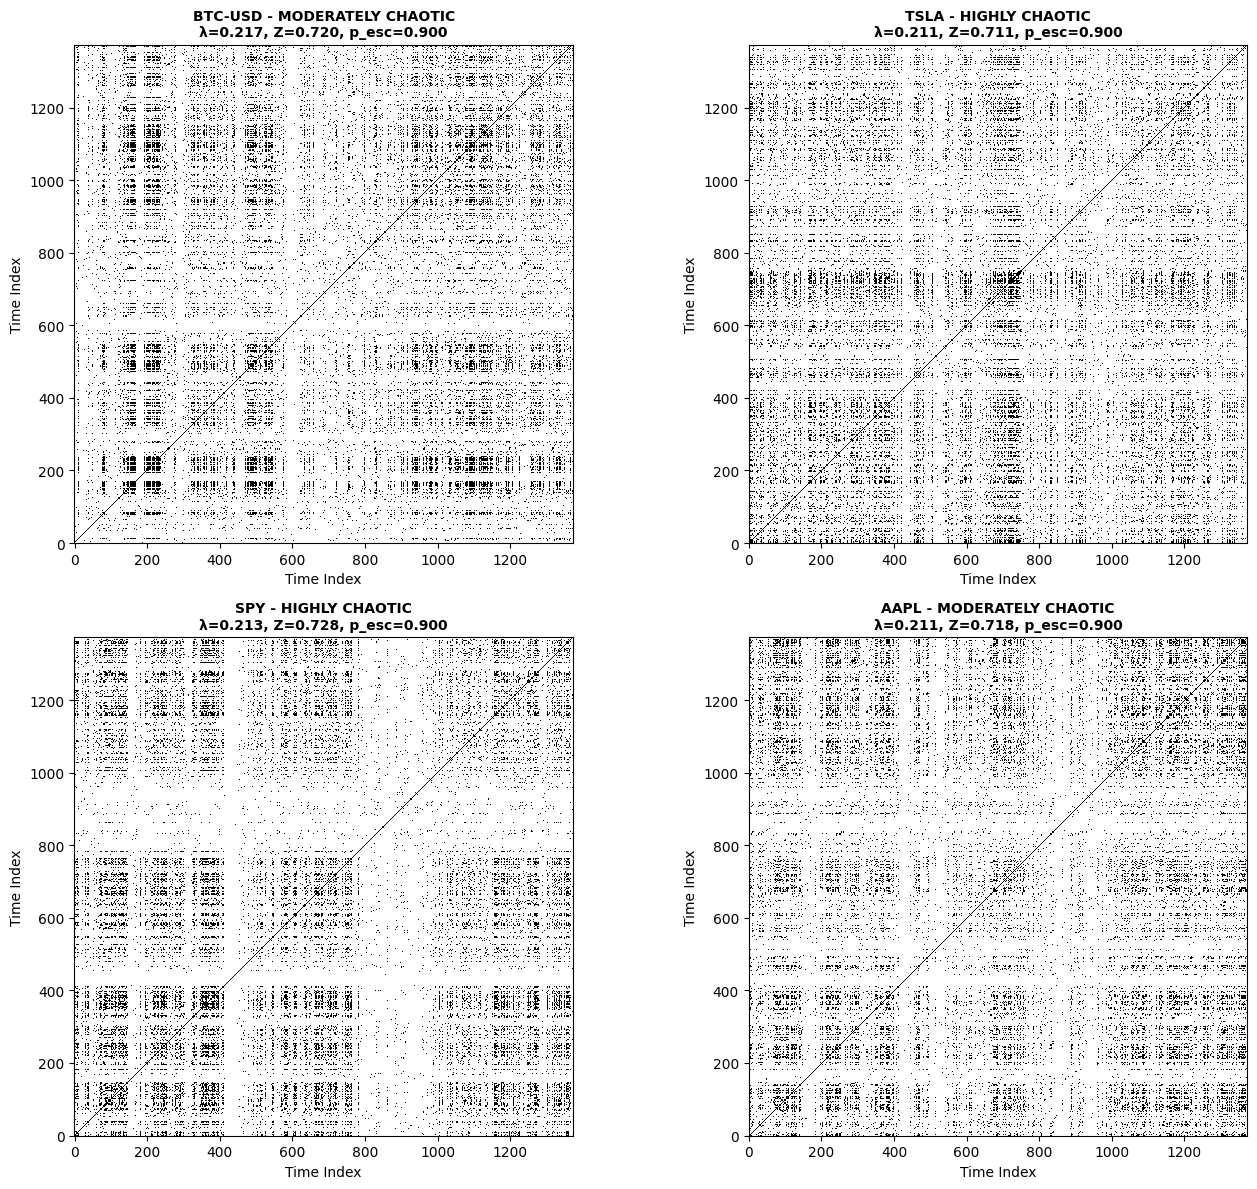

Model comparison saved as 'chaos_model_comparison.png'


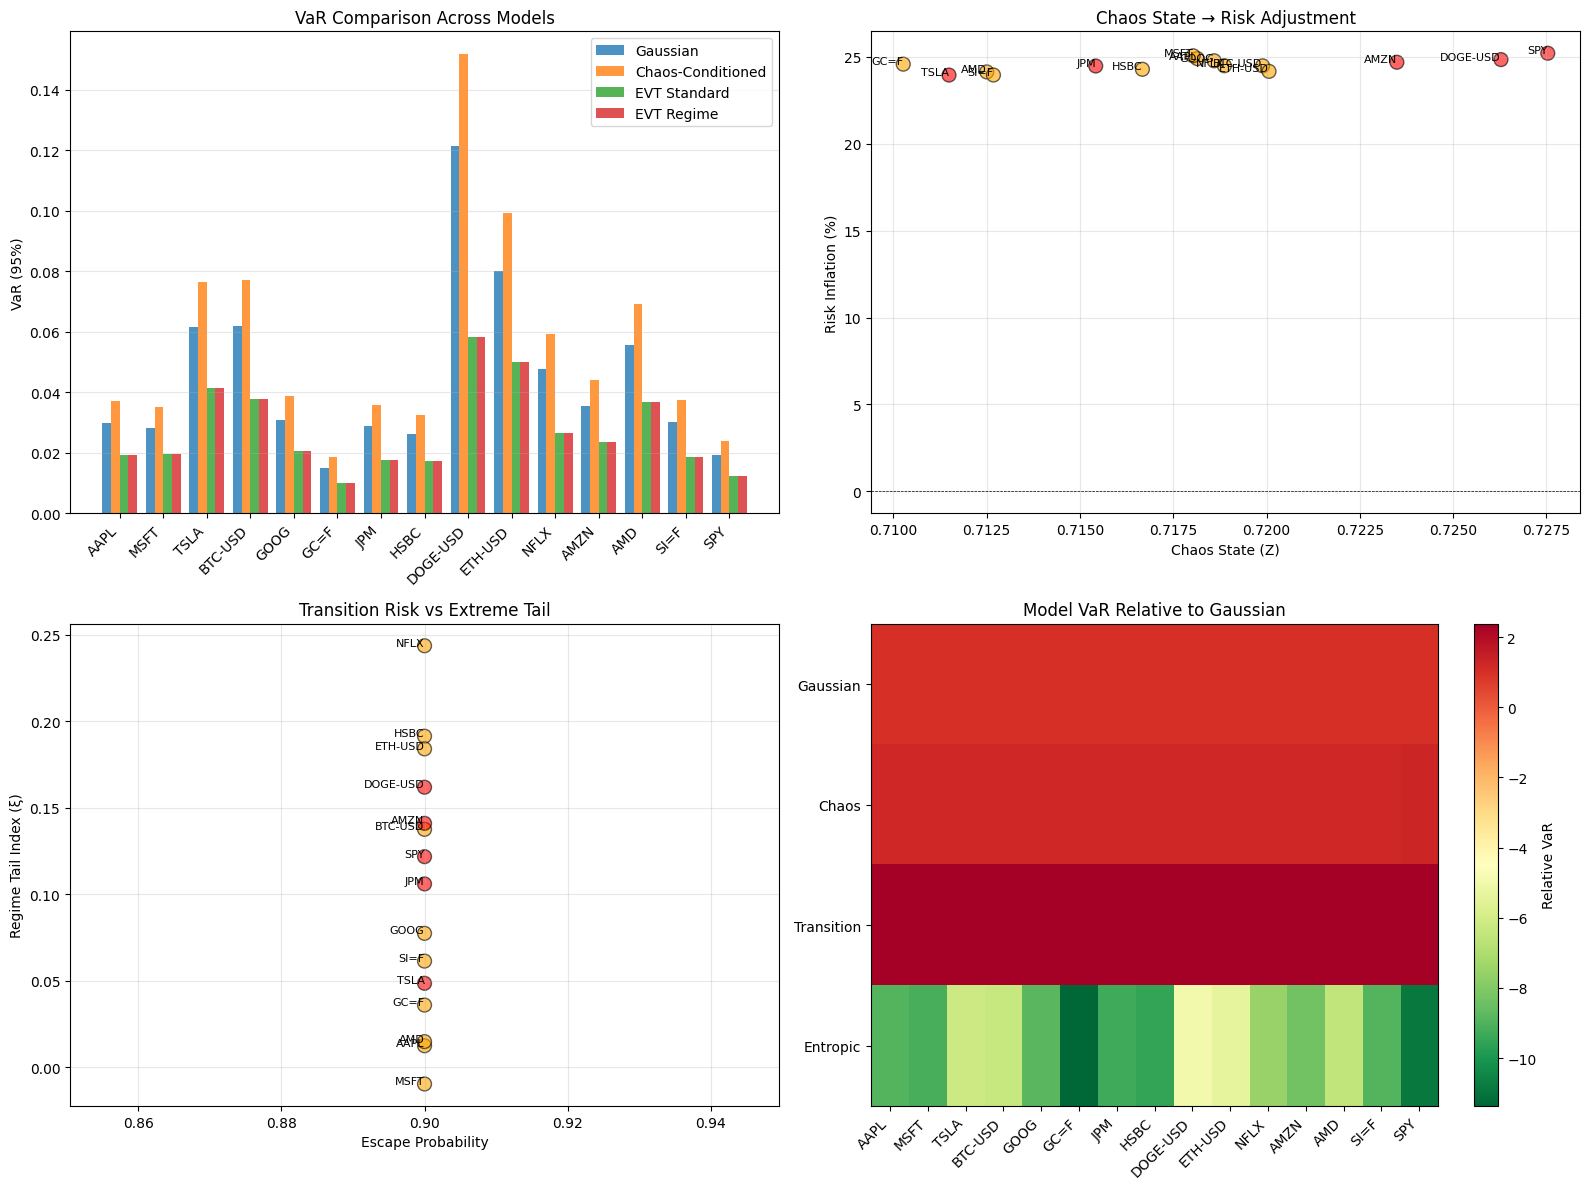



Generating 3D Chaos Volatility Surface...
3D Chaos Volatility Surfaces saved as 'chaos_volatility_surface_3d.png'


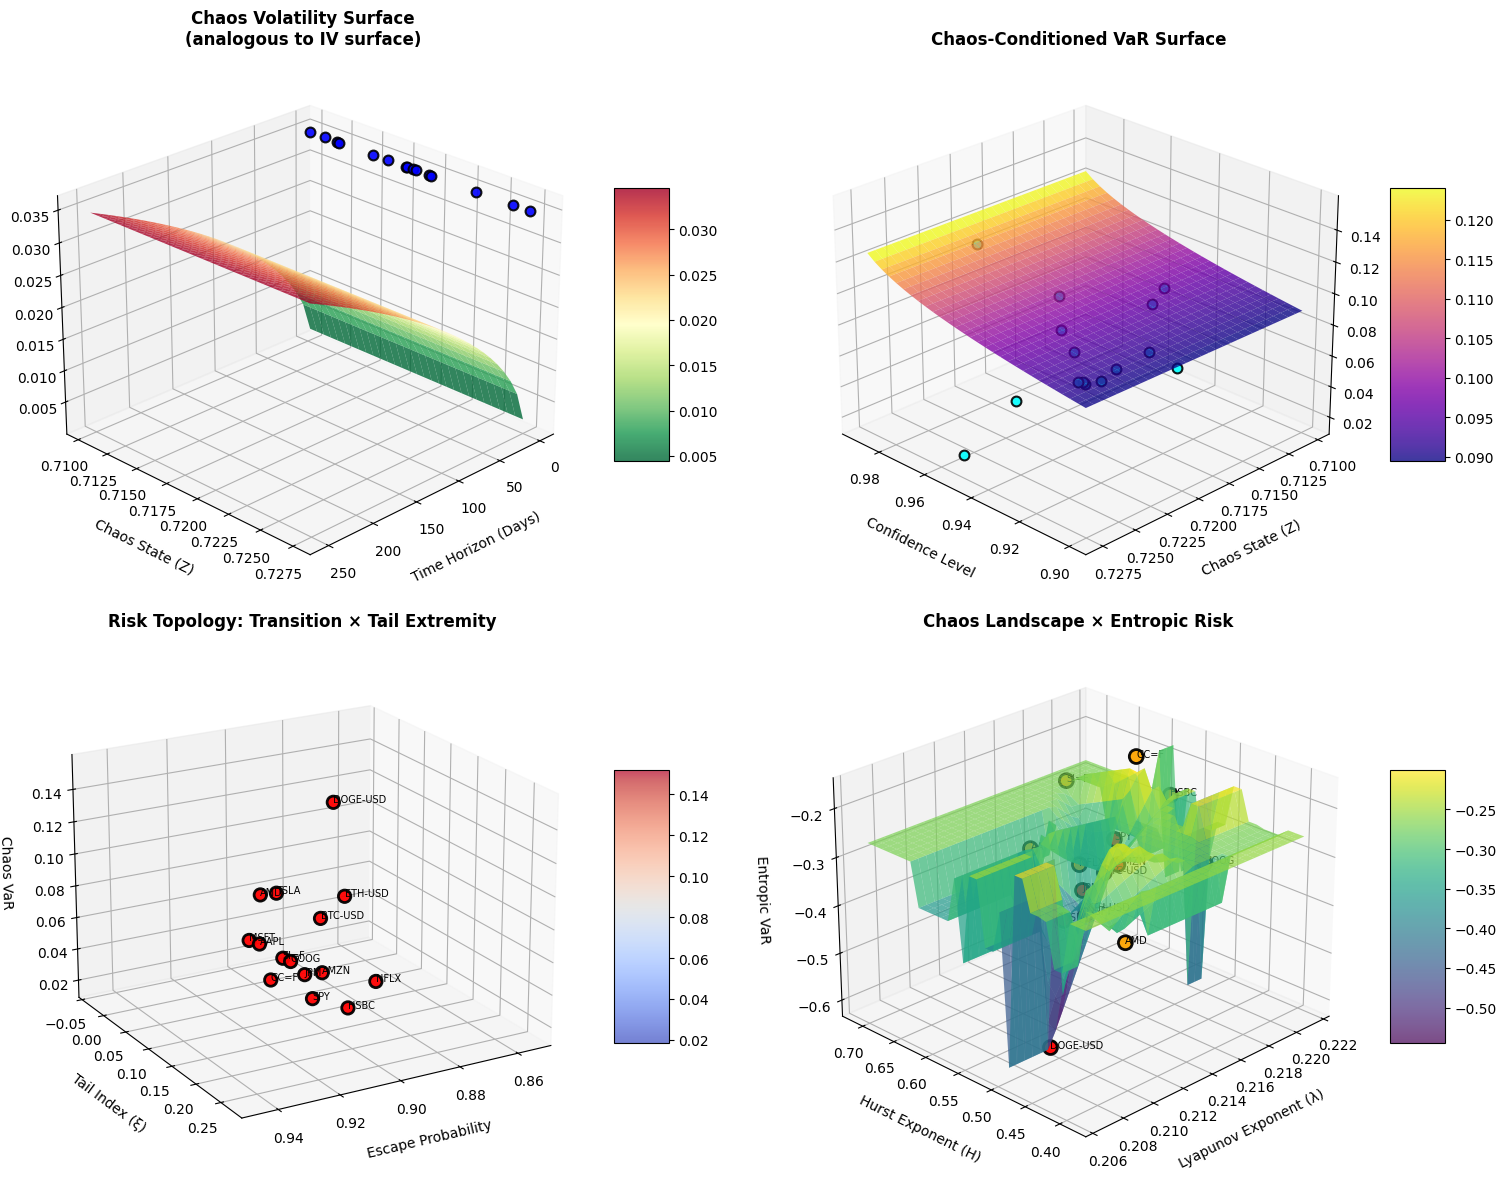


Generating interactive 3D chaos surface...
✓ Created Escape × Tail surface with 15 data points
✓ Interactive 3D surface saved as 'chaos_surface_interactive.html'
  Open this file in a web browser to interact with the 3D surfaces!
  Controls: Drag to rotate, Scroll to zoom, Double-click to reset view

CHAOS-CONDITIONED PROBABILISTIC RISK FRAMEWORK COMPLETE

Key Innovations:
1. Chaos State Index (Z) modulates probability distribution of returns
2. Regime-Conditional EVT isolates structurally extreme states
3. Escape Probability captures transition risk from recurrence geometry
4. Entropic Risk Measure provides distribution-free risk quantification
5. All models maintain returns as primitive (stationary), chaos as probability shifter

3D Visualizations Created:
- Chaos Volatility Surface (analogous to implied volatility surface)
- VaR Surface across chaos states and confidence levels
- Risk Topology: Escape probability × Tail extremity
- Chaos Landscape: Lyapunov × Hurst × Entropic risk


In [9]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.stats import norm, genpareto, gaussian_kde
from scipy.spatial.distance import pdist, squareform
from sklearn.neighbors import NearestNeighbors
from numpy.lib.stride_tricks import sliding_window_view

# -----------------------------
# Parameters
# -----------------------------
tickers = ["AAPL","MSFT","TSLA","BTC-USD","GOOG","GC=F","JPM","HSBC","DOGE-USD","ETH-USD","NFLX","AMZN","AMD","SI=F","SPY"]
start = "2018-01-01"
end   = "2025-01-01"
confidence_level = 0.95
min_exceedances = 20
np.random.seed(42)

# Recurrence plot parameters
embedding_dim = 3
time_delay = 1
recurrence_threshold_percentile = 10

# Chaos modulation parameters
gamma = 0.3  # Volatility sensitivity to chaos
chaos_percentile = 0.75  # Threshold for high-chaos regime

# -----------------------------
# Download data
# -----------------------------
print("Downloading data...")
prices = yf.download(tickers, start=start, end=end)["Close"]

# -----------------------------
# Compute daily log-returns and losses
# -----------------------------
log_returns = np.log(prices / prices.shift(1)).dropna()
losses = -log_returns

# -----------------------------
# Recurrence Plot Functions
# -----------------------------
def embed_time_series(ts, m, tau):
    """Phase space reconstruction using time-delay embedding"""
    ts = np.array(ts)
    N = len(ts)
    M = N - (m - 1) * tau
    embedded = np.zeros((M, m))
    for i in range(m):
        embedded[:, i] = ts[i * tau:i * tau + M]
    return embedded

def recurrence_plot(ts, m=3, tau=1, threshold_percentile=10):
    """Compute recurrence plot matrix"""
    embedded = embed_time_series(ts, m, tau)
    dist_matrix = squareform(pdist(embedded, metric='euclidean'))
    threshold = np.percentile(dist_matrix, threshold_percentile)
    R = (dist_matrix <= threshold).astype(int)
    return R, embedded, threshold

def recurrence_quantification_analysis(R):
    """Compute RQA measures to quantify recurrence plot structure"""
    N = R.shape[0]
    RR = np.sum(R) / (N * N)
    
    min_line_length = 2
    diag_lines = []
    for k in range(1, N):
        diag = np.diag(R, k)
        line_lengths = get_line_lengths(diag)
        diag_lines.extend([l for l in line_lengths if l >= min_line_length])
    
    if len(diag_lines) > 0:
        DET = sum(diag_lines) / np.sum(R)
        L = np.mean(diag_lines)
        L_max = max(diag_lines)
    else:
        DET = 0
        L = 0
        L_max = 0
    
    vert_lines = []
    for j in range(N):
        col = R[:, j]
        line_lengths = get_line_lengths(col)
        vert_lines.extend([l for l in line_lengths if l >= min_line_length])
    
    if len(vert_lines) > 0:
        LAM = sum(vert_lines) / np.sum(R)
        TT = np.mean(vert_lines)
    else:
        LAM = 0
        TT = 0
    
    if len(diag_lines) > 0:
        hist, _ = np.histogram(diag_lines, bins=range(min_line_length, max(diag_lines)+2))
        probs = hist / sum(hist)
        probs = probs[probs > 0]
        ENTR = -np.sum(probs * np.log(probs))
    else:
        ENTR = 0
    
    return {
        'RR': RR, 'DET': DET, 'L': L, 'L_max': L_max,
        'LAM': LAM, 'TT': TT, 'ENTR': ENTR
    }

def get_line_lengths(binary_sequence):
    """Extract lengths of continuous sequences of 1s"""
    lengths = []
    current_length = 0
    for val in binary_sequence:
        if val == 1:
            current_length += 1
        else:
            if current_length > 0:
                lengths.append(current_length)
            current_length = 0
    if current_length > 0:
        lengths.append(current_length)
    return lengths

# -----------------------------
# Hurst exponent
# -----------------------------
def hurst_exponent(ts):
    ts = np.array(ts)
    N = len(ts)
    if N < 20:
        return np.nan
    max_k = N // 2
    rs = []
    lags = range(10, max_k, max(1, max_k//20))
    for lag in lags:
        y = ts[:lag]
        mean_y = np.mean(y)
        Z = np.cumsum(y - mean_y)
        R = np.max(Z) - np.min(Z)
        S = np.std(y)
        if S > 0:
            rs.append(R / S)
    if len(rs) < 2:
        return np.nan
    H = np.polyfit(np.log(lags[:len(rs)]), np.log(rs), 1)[0]
    return H

# -----------------------------
# Lyapunov exponent
# -----------------------------
def lyapunov_exponent(ts, m=2, tau=1, max_t=10, eps=1e-10):
    ts = np.array(ts)
    X = sliding_window_view(ts, window_shape=m)[::tau]
    N = len(X)
    if N <= m + max_t:
        return np.nan

    nbrs = NearestNeighbors(n_neighbors=2, algorithm='kd_tree').fit(X)
    distances, indices = nbrs.kneighbors(X)
    nearest_idx = indices[:, 1]
    dist0 = distances[:, 1]

    L = np.zeros(max_t)
    for i in range(max_t):
        di = []
        max_j = min(len(X)-i, len(nearest_idx))
        for j in range(max_j):
            ni = nearest_idx[j]
            if ni + i >= len(X):
                continue
            d = np.linalg.norm(X[j+i] - X[ni+i])
            di.append(np.log((d + eps)/(dist0[j] + eps)))
        if len(di) > 0:
            L[i] = np.mean(di)
    lam = np.polyfit(np.arange(max_t), L, 1)[0]
    return lam

# -----------------------------
# NEW: Chaos State Index
# -----------------------------
def compute_chaos_state(lam, DET, ENTR, RR):
    """
    Compute latent chaos state Z_t
    High Z → unstable/chaotic regime
    Low Z → stable regime
    """
    Z = (
        np.maximum(lam, 0) * 2.0 +  # Weight positive Lyapunov heavily
        (1 - DET) +                  # Low determinism = high chaos
        ENTR +                       # High entropy = high chaos
        RR                           # Recurrence rate contribution
    )
    return Z

# -----------------------------
# NEW: Chaos-Conditioned Volatility
# -----------------------------
def chaos_modulated_volatility(sigma_base, Z, gamma=0.3):
    """
    σ(Z_t) = σ₀ · exp(γ · Z_t)
    Volatility inflates in chaotic regimes
    """
    return sigma_base * np.exp(gamma * Z)

# -----------------------------
# NEW: Regime-Conditional EVT
# -----------------------------
def compute_regime_evt(x, Z, confidence_level=0.95, min_exceedances=20, chaos_threshold=0.75):
    """
    Fit EVT only on high-chaos regime losses
    This isolates structurally extreme states
    """
    # Select high-chaos regime
    Z_threshold = np.quantile(Z, chaos_threshold)
    high_chaos_mask = Z > Z_threshold
    
    if np.sum(high_chaos_mask) < min_exceedances * 2:
        # Fall back to standard EVT if insufficient data
        return compute_evt(x, confidence_level, min_exceedances)
    
    x_chaos = x[high_chaos_mask]
    return compute_evt(x_chaos, confidence_level, min_exceedances)

# -----------------------------
# Standard EVT function
# -----------------------------
def compute_evt(x, confidence_level=0.95, min_exceedances=20):
    for q in np.linspace(0.90, 0.98, 9):
        u = np.quantile(x, q)
        exceedances = x[x > u] - u
        if len(exceedances) >= min_exceedances:
            break
    else:
        return np.nan, np.nan, np.nan

    Nu, N = len(exceedances), len(x)
    xi, beta, _ = genpareto.fit(exceedances, floc=0)

    p_tail = 1 - confidence_level
    if xi < 1:
        VaR_evt = u + (beta / xi) * ((p_tail * N / Nu) ** (-xi) - 1)
        ES_evt  = (VaR_evt + beta - xi * u) / (1 - xi)
    else:
        VaR_evt, ES_evt = np.nan, np.nan

    return VaR_evt, ES_evt, xi

# -----------------------------
# NEW: Escape Probability from Recurrence
# -----------------------------
def compute_escape_probability(R):
    """
    p_escape(t) = P(X_{t+1} ∉ recurrence core)
    Measures likelihood of regime transition
    """
    if R.shape[0] == 0:
        return 0.0
    # Average non-recurrence per time point
    escape_probs = 1 - R.mean(axis=1)
    return escape_probs.mean()

# -----------------------------
# NEW: Entropic Risk Measure
# -----------------------------
def compute_entropic_risk(returns, embedded):
    """
    ρ_t = -log p(X_t) using KDE
    Higher values = lower probability states = higher risk
    """
    try:
        kde = gaussian_kde(embedded.T)
        log_probs = kde.logpdf(embedded.T)
        entropy_risk = -log_probs.mean()
        return entropy_risk
    except:
        return 0.0

# -----------------------------
# Chaos Classifier
# -----------------------------
def classify_chaos(lam, H, DET, ENTR, L_max):
    """Classify chaotic nature based on multiple indicators"""
    chaos_score = 0
    indicators = []
    
    if not np.isnan(lam):
        if lam > 0.1:
            chaos_score += 3
            indicators.append("Strong positive Lyapunov (highly chaotic)")
        elif lam > 0:
            chaos_score += 2
            indicators.append("Positive Lyapunov (chaotic)")
        else:
            indicators.append("Negative/zero Lyapunov (stable)")
    
    if not np.isnan(H):
        if 0.45 < H < 0.55:
            chaos_score += 2
            indicators.append("Hurst ≈ 0.5 (random walk/chaotic)")
        elif H > 0.5:
            indicators.append(f"Hurst = {H:.3f} (persistent/trending)")
        else:
            indicators.append(f"Hurst = {H:.3f} (mean-reverting)")
    
    if DET < 0.3:
        chaos_score += 1
        indicators.append("Low determinism (stochastic/chaotic)")
    elif DET > 0.7:
        indicators.append("High determinism (regular)")
    
    if ENTR > 2.0:
        chaos_score += 1
        indicators.append("High complexity (chaotic)")
    
    if chaos_score >= 5:
        classification = "HIGHLY CHAOTIC"
    elif chaos_score >= 3:
        classification = "MODERATELY CHAOTIC"
    elif chaos_score >= 1:
        classification = "WEAKLY CHAOTIC"
    else:
        classification = "PREDOMINANTLY STABLE"
    
    return classification, indicators

# -----------------------------
# Main Analysis
# -----------------------------
print("\nAnalyzing time series with chaos-conditioned risk...")
results = []

for ticker in tickers:
    print(f"Processing {ticker}...")
    x = losses[ticker].dropna().values
    returns = log_returns[ticker].dropna().values
    
    mu, sigma = x.mean(), x.std()

    # === Standard Gaussian VaR/ES ===
    z = norm.ppf(confidence_level)
    VaR_gaussian = mu + sigma * z
    ES_gaussian  = mu + sigma * norm.pdf(z) / (1 - confidence_level)

    # === Chaos Metrics ===
    H = hurst_exponent(returns)
    lam = lyapunov_exponent(returns)
    
    R, embedded, threshold = recurrence_plot(returns, m=embedding_dim, 
                                            tau=time_delay, 
                                            threshold_percentile=recurrence_threshold_percentile)
    rqa = recurrence_quantification_analysis(R)
    
    # === NEW: Compute Chaos State ===
    Z = compute_chaos_state(lam if not np.isnan(lam) else 0, 
                           rqa['DET'], rqa['ENTR'], rqa['RR'])
    Z_normalized = (Z - 0) / (1 + abs(Z))  # Normalize for stability
    
    # === NEW: Chaos-Modulated Volatility ===
    sigma_chaos = chaos_modulated_volatility(sigma, Z_normalized, gamma)
    
    # === NEW: Chaos-Conditioned VaR/ES ===
    VaR_chaos = mu + sigma_chaos * z
    ES_chaos = mu + sigma_chaos * norm.pdf(z) / (1 - confidence_level)
    
    # === Standard EVT ===
    VaR_evt_standard, ES_evt_standard, xi_standard = compute_evt(x, confidence_level, min_exceedances)
    
    # === NEW: Regime-Conditional EVT ===
    # Create time-aligned chaos index for regime selection
    Z_series = np.full(len(x), Z_normalized)  # Broadcast chaos state
    VaR_evt_regime, ES_evt_regime, xi_regime = compute_regime_evt(
        x, Z_series, confidence_level, min_exceedances, chaos_percentile
    )
    
    # === NEW: Escape Probability ===
    p_escape = compute_escape_probability(R)
    
    # === NEW: Entropic Risk ===
    rho = compute_entropic_risk(returns, embedded)
    
    # === NEW: Transition-Aware Risk ===
    VaR_transition = VaR_chaos * (1 + p_escape)
    
    # === NEW: Entropic VaR ===
    VaR_entropic = VaR_chaos * (1 + rho)
    
    # Classify chaos
    chaos_class, chaos_indicators = classify_chaos(lam, H, rqa['DET'], rqa['ENTR'], rqa['L_max'])

    results.append({
        "Ticker": ticker,
        # Standard measures
        "Gaussian_VaR": VaR_gaussian,
        "Gaussian_ES": ES_gaussian,
        # Chaos-conditioned measures
        "Chaos_VaR": VaR_chaos,
        "Chaos_ES": ES_chaos,
        "Transition_VaR": VaR_transition,
        "Entropic_VaR": VaR_entropic,
        # Standard EVT
        "EVT_VaR_Standard": VaR_evt_standard,
        "EVT_ES_Standard": ES_evt_standard,
        "GPD_xi_Standard": xi_standard,
        # Regime-conditional EVT
        "EVT_VaR_Regime": VaR_evt_regime,
        "EVT_ES_Regime": ES_evt_regime,
        "GPD_xi_Regime": xi_regime,
        # Chaos metrics
        "Chaos_State_Z": Z_normalized,
        "Hurst": H,
        "Lyapunov": lam,
        "Escape_Prob": p_escape,
        "Entropic_Risk": rho,
        # RQA
        "RQA_RR": rqa['RR'],
        "RQA_DET": rqa['DET'],
        "RQA_L": rqa['L'],
        "RQA_LAM": rqa['LAM'],
        "RQA_ENTR": rqa['ENTR'],
        # Classification
        "Chaos_Class": chaos_class,
        "Chaos_Indicators": "; ".join(chaos_indicators),
        "Recurrence_Matrix": R
    })

# -----------------------------
# Create summary
# -----------------------------
summary = pd.DataFrame(results)

# Enhanced risk comments
risk_comments = []
for i, row in summary.iterrows():
    comment = f"{row['Chaos_Class']} (Z={row['Chaos_State_Z']:.3f}): "
    
    # Compare models
    improvement_chaos = ((row['Chaos_VaR'] - row['Gaussian_VaR']) / row['Gaussian_VaR'] * 100)
    comment += f"Chaos-VaR +{improvement_chaos:.1f}% vs Gaussian; "
    
    if not np.isnan(row['EVT_VaR_Regime']):
        comment += f"Regime-EVT={row['EVT_VaR_Regime']:.4f} (ξ={row['GPD_xi_Regime']:.3f}); "
    
    comment += f"p_escape={row['Escape_Prob']:.3f}, ρ={row['Entropic_Risk']:.3f}"
    risk_comments.append(comment)

summary['Risk_Summary'] = risk_comments

# Display results
pd.set_option('display.max_colwidth', None)
print("\n" + "="*140)
print("CHAOS-CONDITIONED RISK ANALYSIS")
print("="*140)
print(summary[['Ticker', 'Gaussian_VaR', 'Chaos_VaR', 'EVT_VaR_Standard', 'EVT_VaR_Regime', 
               'Chaos_State_Z', 'Escape_Prob']].to_string(index=False))

print("\n" + "="*140)
print("MODEL COMPARISON: VaR at 95% Confidence")
print("="*140)
comparison = summary[['Ticker', 'Gaussian_VaR', 'Chaos_VaR', 'Transition_VaR', 
                      'Entropic_VaR', 'EVT_VaR_Regime', 'Chaos_Class']].copy()
print(comparison.to_string(index=False))

print("\n" + "="*140)
print("DETAILED RISK SUMMARIES")
print("="*140)
for i, row in summary.iterrows():
    print(f"\n{row['Ticker']}:")
    print(f"  {row['Risk_Summary']}")
    print(f"  Indicators: {row['Chaos_Indicators']}")

# -----------------------------
# Visualizations
# -----------------------------
print("\n\nGenerating visualizations...")

# 1. Recurrence plots for selected tickers
selected_tickers = ["BTC-USD", "TSLA", "SPY", "AAPL"]
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.flatten()

for idx, ticker in enumerate(selected_tickers):
    if ticker in summary['Ticker'].values:
        row = summary[summary['Ticker'] == ticker].iloc[0]
        R = row['Recurrence_Matrix']
        
        ax = axes[idx]
        im = ax.imshow(R, cmap='binary', origin='lower', interpolation='nearest')
        ax.set_title(f"{ticker} - {row['Chaos_Class']}\nλ={row['Lyapunov']:.3f}, Z={row['Chaos_State_Z']:.3f}, p_esc={row['Escape_Prob']:.3f}", 
                    fontsize=10, fontweight='bold')
        ax.set_xlabel('Time Index')
        ax.set_ylabel('Time Index')
        ax.grid(False)

plt.tight_layout()
plt.savefig('recurrence_plots_chaos.png', dpi=300, bbox_inches='tight')
print("Recurrence plots saved as 'recurrence_plots_chaos.png'")
plt.show()

# 2. Model comparison
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# VaR comparison
ax1 = axes[0, 0]
x_pos = np.arange(len(summary))
width = 0.2
ax1.bar(x_pos - 1.5*width, summary['Gaussian_VaR'], width, label='Gaussian', alpha=0.8)
ax1.bar(x_pos - 0.5*width, summary['Chaos_VaR'], width, label='Chaos-Conditioned', alpha=0.8)
ax1.bar(x_pos + 0.5*width, summary['EVT_VaR_Standard'], width, label='EVT Standard', alpha=0.8)
ax1.bar(x_pos + 1.5*width, summary['EVT_VaR_Regime'], width, label='EVT Regime', alpha=0.8)
ax1.set_xticks(x_pos)
ax1.set_xticklabels(summary['Ticker'], rotation=45, ha='right')
ax1.set_ylabel('VaR (95%)')
ax1.set_title('VaR Comparison Across Models')
ax1.legend()
ax1.grid(True, alpha=0.3, axis='y')

# Chaos state vs risk inflation
ax2 = axes[0, 1]
colors = ['red' if 'HIGHLY' in c else 'orange' if 'MODERATELY' in c else 'yellow' if 'WEAKLY' in c else 'green' 
          for c in summary['Chaos_Class']]
risk_inflation = (summary['Chaos_VaR'] - summary['Gaussian_VaR']) / summary['Gaussian_VaR'] * 100
ax2.scatter(summary['Chaos_State_Z'], risk_inflation, c=colors, s=100, alpha=0.6, edgecolors='black')
for i, txt in enumerate(summary['Ticker']):
    ax2.annotate(txt, (summary['Chaos_State_Z'].iloc[i], risk_inflation.iloc[i]), 
                fontsize=8, ha='right')
ax2.axhline(0, color='black', linestyle='--', linewidth=0.5)
ax2.set_xlabel('Chaos State (Z)')
ax2.set_ylabel('Risk Inflation (%)')
ax2.set_title('Chaos State → Risk Adjustment')
ax2.grid(True, alpha=0.3)

# Escape probability vs regime EVT
ax3 = axes[1, 0]
valid_regime = ~np.isnan(summary['EVT_VaR_Regime'])
ax3.scatter(summary.loc[valid_regime, 'Escape_Prob'], 
           summary.loc[valid_regime, 'GPD_xi_Regime'], 
           c=[colors[i] for i in summary[valid_regime].index], 
           s=100, alpha=0.6, edgecolors='black')
for i in summary[valid_regime].index:
    ax3.annotate(summary.loc[i, 'Ticker'], 
                (summary.loc[i, 'Escape_Prob'], summary.loc[i, 'GPD_xi_Regime']), 
                fontsize=8, ha='right')
ax3.set_xlabel('Escape Probability')
ax3.set_ylabel('Regime Tail Index (ξ)')
ax3.set_title('Transition Risk vs Extreme Tail')
ax3.grid(True, alpha=0.3)

# Model effectiveness heatmap
ax4 = axes[1, 1]
model_data = summary[['Gaussian_VaR', 'Chaos_VaR', 'Transition_VaR', 'Entropic_VaR']].copy()
model_data = model_data.div(model_data['Gaussian_VaR'], axis=0)  # Normalize to Gaussian
im = ax4.imshow(model_data.T, cmap='RdYlGn_r', aspect='auto')
ax4.set_yticks(range(4))
ax4.set_yticklabels(['Gaussian', 'Chaos', 'Transition', 'Entropic'])
ax4.set_xticks(range(len(summary)))
ax4.set_xticklabels(summary['Ticker'], rotation=45, ha='right')
ax4.set_title('Model VaR Relative to Gaussian')
plt.colorbar(im, ax=ax4, label='Relative VaR')

plt.tight_layout()
plt.savefig('chaos_model_comparison.png', dpi=300, bbox_inches='tight')
print("Model comparison saved as 'chaos_model_comparison.png'")
plt.show()

# -----------------------------
# 3D Chaos Volatility Surface (Like Implied Vol Surface)
# -----------------------------
print("\n\nGenerating 3D Chaos Volatility Surface...")

from mpl_toolkits.mplot3d import Axes3D
from matplotlib import cm
from scipy.interpolate import griddata

# Create synthetic time-to-risk and chaos-level grid
# This mimics the structure of an implied volatility surface
# X-axis: Time horizon (days)
# Y-axis: Chaos intensity level
# Z-axis: Risk-adjusted volatility

fig = plt.figure(figsize=(16, 12))

# === Plot 1: Chaos Volatility Surface ===
ax1 = fig.add_subplot(2, 2, 1, projection='3d')

# Create grid
chaos_levels = np.linspace(summary['Chaos_State_Z'].min(), summary['Chaos_State_Z'].max(), 30)
time_horizons = np.linspace(1, 252, 30)  # 1 day to 1 year
X_grid, Y_grid = np.meshgrid(time_horizons, chaos_levels)

# Compute volatility surface using chaos modulation
# σ(Z, t) = σ_base * exp(γ * Z) * sqrt(t)  (time-scaled)
sigma_base_mean = summary['Gaussian_VaR'].std()  # Representative base volatility
Z_grid = np.zeros_like(X_grid)

for i, chaos_z in enumerate(chaos_levels):
    for j, t in enumerate(time_horizons):
        # Chaos-modulated volatility with time scaling
        sigma_chaos_t = sigma_base_mean * np.exp(gamma * chaos_z) * np.sqrt(t/252)
        Z_grid[i, j] = sigma_chaos_t

# Plot surface
surf1 = ax1.plot_surface(X_grid, Y_grid, Z_grid, cmap=cm.RdYlGn_r, 
                         linewidth=0, antialiased=True, alpha=0.8)

# Overlay actual data points
for idx, row in summary.iterrows():
    # Plot at 1-day horizon
    ax1.scatter([1], [row['Chaos_State_Z']], 
               [sigma_base_mean * np.exp(gamma * row['Chaos_State_Z'])],
               color='blue', s=50, edgecolors='black', linewidths=1.5, alpha=0.9)

ax1.set_xlabel('Time Horizon (Days)', fontsize=10, labelpad=10)
ax1.set_ylabel('Chaos State (Z)', fontsize=10, labelpad=10)
ax1.set_zlabel('Risk-Adjusted Volatility', fontsize=10, labelpad=10)
ax1.set_title('Chaos Volatility Surface\n(analogous to IV surface)', fontsize=12, fontweight='bold')
ax1.view_init(elev=25, azim=45)
fig.colorbar(surf1, ax=ax1, shrink=0.5, aspect=5)

# === Plot 2: VaR Surface ===
ax2 = fig.add_subplot(2, 2, 2, projection='3d')

# VaR surface: VaR(Z, confidence_level)
confidence_levels = np.linspace(0.90, 0.99, 30)
chaos_levels_var = np.linspace(summary['Chaos_State_Z'].min(), summary['Chaos_State_Z'].max(), 30)
X_var, Y_var = np.meshgrid(confidence_levels, chaos_levels_var)
Z_var = np.zeros_like(X_var)

mu_mean = summary['Gaussian_VaR'].mean()
for i, chaos_z in enumerate(chaos_levels_var):
    for j, conf in enumerate(confidence_levels):
        sigma_chaos = sigma_base_mean * np.exp(gamma * chaos_z)
        z_score = norm.ppf(conf)
        VaR = mu_mean + sigma_chaos * z_score
        Z_var[i, j] = VaR

surf2 = ax2.plot_surface(X_var, Y_var, Z_var, cmap=cm.plasma,
                         linewidth=0, antialiased=True, alpha=0.8)

# Overlay actual VaR points
for idx, row in summary.iterrows():
    ax2.scatter([confidence_level], [row['Chaos_State_Z']], [row['Chaos_VaR']],
               color='cyan', s=50, edgecolors='black', linewidths=1.5, alpha=0.9)

ax2.set_xlabel('Confidence Level', fontsize=10, labelpad=10)
ax2.set_ylabel('Chaos State (Z)', fontsize=10, labelpad=10)
ax2.set_zlabel('VaR', fontsize=10, labelpad=10)
ax2.set_title('Chaos-Conditioned VaR Surface', fontsize=12, fontweight='bold')
ax2.view_init(elev=25, azim=135)
fig.colorbar(surf2, ax=ax2, shrink=0.5, aspect=5)

# === Plot 3: Escape Probability × Tail Index Surface ===
ax3 = fig.add_subplot(2, 2, 3, projection='3d')

# Create interpolated surface from actual data
valid_data = summary[~np.isnan(summary['GPD_xi_Regime'])].copy()

if len(valid_data) > 3:
    try:
        # Create grid with padding to avoid edge issues
        escape_margin = (valid_data['Escape_Prob'].max() - valid_data['Escape_Prob'].min()) * 0.1
        xi_margin = (valid_data['GPD_xi_Regime'].max() - valid_data['GPD_xi_Regime'].min()) * 0.1
        
        escape_range = np.linspace(valid_data['Escape_Prob'].min() - escape_margin, 
                                   valid_data['Escape_Prob'].max() + escape_margin, 30)
        xi_range = np.linspace(valid_data['GPD_xi_Regime'].min() - xi_margin, 
                              valid_data['GPD_xi_Regime'].max() + xi_margin, 30)
        X_esc, Y_xi = np.meshgrid(escape_range, xi_range)
        
        # Interpolate chaos VaR - try linear first, fallback to nearest
        points = valid_data[['Escape_Prob', 'GPD_xi_Regime']].values
        values = valid_data['Chaos_VaR'].values
        
        try:
            Z_risk = griddata(points, values, (X_esc, Y_xi), method='linear')
        except:
            Z_risk = griddata(points, values, (X_esc, Y_xi), method='nearest')
        
        # Fill any NaN values with nearest neighbor
        if np.any(np.isnan(Z_risk)):
            Z_risk_filled = griddata(points, values, (X_esc, Y_xi), method='nearest')
            Z_risk = np.where(np.isnan(Z_risk), Z_risk_filled, Z_risk)
        
        surf3 = ax3.plot_surface(X_esc, Y_xi, Z_risk, cmap=cm.coolwarm,
                                 linewidth=0, antialiased=True, alpha=0.7)
        fig.colorbar(surf3, ax=ax3, shrink=0.5, aspect=5)
    except Exception as e:
        print(f"Warning: Could not create interpolated surface: {e}")
        print("Falling back to scatter plot only")
    
    # Overlay actual points (always show these)
    ax3.scatter(valid_data['Escape_Prob'], valid_data['GPD_xi_Regime'], 
               valid_data['Chaos_VaR'],
               color='red', s=80, edgecolors='black', linewidths=2, alpha=0.95)
    
    # Add ticker labels
    for idx, row in valid_data.iterrows():
        ax3.text(row['Escape_Prob'], row['GPD_xi_Regime'], row['Chaos_VaR'],
                row['Ticker'], fontsize=7)
    
    ax3.set_xlabel('Escape Probability', fontsize=10, labelpad=10)
    ax3.set_ylabel('Tail Index (ξ)', fontsize=10, labelpad=10)
    ax3.set_zlabel('Chaos VaR', fontsize=10, labelpad=10)
    ax3.set_title('Risk Topology: Transition × Tail Extremity', fontsize=12, fontweight='bold')
    ax3.view_init(elev=20, azim=60)

# === Plot 4: Lyapunov × Hurst × Risk Surface ===
ax4 = fig.add_subplot(2, 2, 4, projection='3d')

valid_chaos = summary[~np.isnan(summary['Lyapunov']) & ~np.isnan(summary['Hurst'])].copy()

if len(valid_chaos) > 3:
    try:
        # Create grid with padding
        lam_margin = (valid_chaos['Lyapunov'].max() - valid_chaos['Lyapunov'].min()) * 0.1
        hurst_margin = (valid_chaos['Hurst'].max() - valid_chaos['Hurst'].min()) * 0.1
        
        lam_range = np.linspace(valid_chaos['Lyapunov'].min() - lam_margin, 
                               valid_chaos['Lyapunov'].max() + lam_margin, 30)
        hurst_range = np.linspace(valid_chaos['Hurst'].min() - hurst_margin, 
                                 valid_chaos['Hurst'].max() + hurst_margin, 30)
        X_lam, Y_hurst = np.meshgrid(lam_range, hurst_range)
        
        # Interpolate risk measure
        points = valid_chaos[['Lyapunov', 'Hurst']].values
        values = valid_chaos['Entropic_VaR'].values
        
        try:
            Z_entropic = griddata(points, values, (X_lam, Y_hurst), method='linear')
        except:
            Z_entropic = griddata(points, values, (X_lam, Y_hurst), method='nearest')
        
        # Fill NaN values
        if np.any(np.isnan(Z_entropic)):
            Z_entropic_filled = griddata(points, values, (X_lam, Y_hurst), method='nearest')
            Z_entropic = np.where(np.isnan(Z_entropic), Z_entropic_filled, Z_entropic)
        
        surf4 = ax4.plot_surface(X_lam, Y_hurst, Z_entropic, cmap=cm.viridis,
                                 linewidth=0, antialiased=True, alpha=0.7)
        fig.colorbar(surf4, ax=ax4, shrink=0.5, aspect=5)
    except Exception as e:
        print(f"Warning: Could not create Lyapunov surface: {e}")
        print("Falling back to scatter plot only")
    
    # Overlay actual points with color coding (always show)
    colors_chaos = ['red' if 'HIGHLY' in c else 'orange' if 'MODERATELY' in c 
                   else 'yellow' if 'WEAKLY' in c else 'green' 
                   for c in valid_chaos['Chaos_Class']]
    
    ax4.scatter(valid_chaos['Lyapunov'], valid_chaos['Hurst'], 
               valid_chaos['Entropic_VaR'],
               c=colors_chaos, s=100, edgecolors='black', linewidths=2, alpha=0.95)
    
    # Add ticker labels
    for idx, row in valid_chaos.iterrows():
        ax4.text(row['Lyapunov'], row['Hurst'], row['Entropic_VaR'],
                row['Ticker'], fontsize=7)
    
    ax4.set_xlabel('Lyapunov Exponent (λ)', fontsize=10, labelpad=10)
    ax4.set_ylabel('Hurst Exponent (H)', fontsize=10, labelpad=10)
    ax4.set_zlabel('Entropic VaR', fontsize=10, labelpad=10)
    ax4.set_title('Chaos Landscape × Entropic Risk', fontsize=12, fontweight='bold')
    ax4.view_init(elev=25, azim=225)

plt.tight_layout()
plt.savefig('chaos_volatility_surface_3d.png', dpi=300, bbox_inches='tight')
print("3D Chaos Volatility Surfaces saved as 'chaos_volatility_surface_3d.png'")
plt.show()

# -----------------------------
# Interactive 3D Plot (HTML export for rotation/zoom)
# -----------------------------
print("\nGenerating interactive 3D chaos surface...")

try:
    import plotly.graph_objects as go
    from plotly.subplots import make_subplots
    
    # Create interactive subplots
    fig_interactive = make_subplots(
        rows=2, cols=2,
        subplot_titles=('Chaos Volatility Surface', 
                       'VaR Surface by Chaos & Confidence',
                       'Escape Probability × Tail Risk',
                       'Lyapunov × Hurst × Entropic Risk'),
        specs=[[{'type': 'surface'}, {'type': 'surface'}],
               [{'type': 'surface'}, {'type': 'surface'}]],
        vertical_spacing=0.12,
        horizontal_spacing=0.1
    )
    
    # Surface 1: Chaos Volatility
    fig_interactive.add_trace(
        go.Surface(x=X_grid, y=Y_grid, z=Z_grid, 
                  colorscale='RdYlGn_r', showscale=True,
                  name='Chaos Vol Surface',
                  colorbar=dict(x=0.46, len=0.4, y=0.8)),
        row=1, col=1
    )
    
    # Add scatter points for volatility surface
    fig_interactive.add_trace(
        go.Scatter3d(
            x=[1]*len(summary),
            y=summary['Chaos_State_Z'],
            z=sigma_base_mean * np.exp(gamma * summary['Chaos_State_Z']),
            mode='markers+text',
            marker=dict(size=6, color='blue', symbol='circle', 
                       line=dict(color='black', width=2)),
            text=summary['Ticker'],
            textposition='top center',
            textfont=dict(size=8),
            name='Assets',
            showlegend=False
        ),
        row=1, col=1
    )
    
    # Surface 2: VaR Surface
    fig_interactive.add_trace(
        go.Surface(x=X_var, y=Y_var, z=Z_var,
                  colorscale='Plasma', showscale=True,
                  name='VaR Surface',
                  colorbar=dict(x=1.02, len=0.4, y=0.8)),
        row=1, col=2
    )
    
    # Add scatter points for VaR surface
    fig_interactive.add_trace(
        go.Scatter3d(
            x=[confidence_level]*len(summary),
            y=summary['Chaos_State_Z'],
            z=summary['Chaos_VaR'],
            mode='markers+text',
            marker=dict(size=6, color='cyan', symbol='circle',
                       line=dict(color='black', width=2)),
            text=summary['Ticker'],
            textposition='top center',
            textfont=dict(size=8),
            name='Assets',
            showlegend=False
        ),
        row=1, col=2
    )
    
    # Surface 3: Escape × Tail - Create interpolated surface
    if len(valid_data) > 3:
        try:
            # Create a denser grid for better interpolation
            n_points = 40
            
            # Get data range with generous padding
            escape_min, escape_max = valid_data['Escape_Prob'].min(), valid_data['Escape_Prob'].max()
            xi_min, xi_max = valid_data['GPD_xi_Regime'].min(), valid_data['GPD_xi_Regime'].max()
            
            escape_range_plot = escape_max - escape_min
            xi_range_plot = xi_max - xi_min
            
            # Add 20% padding on each side
            escape_range_int = np.linspace(escape_min - 0.2*escape_range_plot, 
                                           escape_max + 0.2*escape_range_plot, n_points)
            xi_range_int = np.linspace(xi_min - 0.2*xi_range_plot, 
                                       xi_max + 0.2*xi_range_plot, n_points)
            X_esc_int, Y_xi_int = np.meshgrid(escape_range_int, xi_range_int)
            
            points_esc = valid_data[['Escape_Prob', 'GPD_xi_Regime']].values
            values_esc = valid_data['Chaos_VaR'].values
            
            # Use Radial Basis Function for smoother interpolation
            from scipy.interpolate import Rbf
            try:
                rbf = Rbf(points_esc[:, 0], points_esc[:, 1], values_esc, function='multiquadric', smooth=0.1)
                Z_risk_int = rbf(X_esc_int, Y_xi_int)
            except:
                # Fallback to griddata
                Z_risk_int = griddata(points_esc, values_esc, (X_esc_int, Y_xi_int), method='linear')
                if np.any(np.isnan(Z_risk_int)):
                    Z_risk_filled = griddata(points_esc, values_esc, (X_esc_int, Y_xi_int), method='nearest')
                    Z_risk_int = np.where(np.isnan(Z_risk_int), Z_risk_filled, Z_risk_int)
            
            # Smooth the surface slightly
            from scipy.ndimage import gaussian_filter
            Z_risk_int = gaussian_filter(Z_risk_int, sigma=0.8)
            
            fig_interactive.add_trace(
                go.Surface(
                    x=X_esc_int, 
                    y=Y_xi_int, 
                    z=Z_risk_int,
                    colorscale='Reds', 
                    showscale=True,
                    name='Risk Surface',
                    colorbar=dict(x=0.46, len=0.4, y=0.25, title='Chaos VaR'),
                    opacity=0.85,
                    contours=dict(
                        z=dict(show=True, usecolormap=True, highlightcolor="limegreen", project=dict(z=True))
                    )
                ),
                row=2, col=1
            )
            print(f"✓ Created Escape × Tail surface with {len(valid_data)} data points")
        except Exception as e:
            print(f"⚠ Could not create escape surface in interactive plot: {e}")
            print("  Showing scatter points only for this subplot")
        
        # Add scatter points (always show these)
        # Create color array based on chaos classification
        point_colors = []
        for idx in valid_data.index:
            chaos_class = valid_data.loc[idx, 'Chaos_Class']
            if 'HIGHLY' in chaos_class:
                point_colors.append('darkred')
            elif 'MODERATELY' in chaos_class:
                point_colors.append('orangered')
            elif 'WEAKLY' in chaos_class:
                point_colors.append('gold')
            else:
                point_colors.append('lightgreen')
        
        fig_interactive.add_trace(
            go.Scatter3d(
                x=valid_data['Escape_Prob'],
                y=valid_data['GPD_xi_Regime'],
                z=valid_data['Chaos_VaR'],
                mode='markers+text',
                marker=dict(
                    size=10,
                    color=point_colors,
                    line=dict(color='black', width=2),
                    symbol='diamond'
                ),
                text=valid_data['Ticker'],
                textposition='top center',
                textfont=dict(size=9, color='black'),
                name='Assets',
                showlegend=False,
                hovertemplate='<b>%{text}</b><br>' +
                             'Escape Prob: %{x:.3f}<br>' +
                             'Tail ξ: %{y:.3f}<br>' +
                             'Chaos VaR: %{z:.4f}<br>' +
                             '<extra></extra>'
            ),
            row=2, col=1
        )
    else:
        print(f"⚠ Only {len(valid_data)} data points for Escape × Tail plot - need more for surface")
    
    # Surface 4: Lyapunov × Hurst - Create interpolated surface
    if len(valid_chaos) > 3:
        try:
            # Create interpolated surface
            lam_margin = (valid_chaos['Lyapunov'].max() - valid_chaos['Lyapunov'].min()) * 0.1
            hurst_margin = (valid_chaos['Hurst'].max() - valid_chaos['Hurst'].min()) * 0.1
            
            lam_range_int = np.linspace(valid_chaos['Lyapunov'].min() - lam_margin, 
                                        valid_chaos['Lyapunov'].max() + lam_margin, 25)
            hurst_range_int = np.linspace(valid_chaos['Hurst'].min() - hurst_margin, 
                                          valid_chaos['Hurst'].max() + hurst_margin, 25)
            X_lam_int, Y_hurst_int = np.meshgrid(lam_range_int, hurst_range_int)
            
            points_chaos = valid_chaos[['Lyapunov', 'Hurst']].values
            values_chaos = valid_chaos['Entropic_VaR'].values
            
            try:
                Z_entropic_int = griddata(points_chaos, values_chaos, (X_lam_int, Y_hurst_int), method='linear')
            except:
                Z_entropic_int = griddata(points_chaos, values_chaos, (X_lam_int, Y_hurst_int), method='nearest')
            
            if np.any(np.isnan(Z_entropic_int)):
                Z_entropic_filled = griddata(points_chaos, values_chaos, (X_lam_int, Y_hurst_int), method='nearest')
                Z_entropic_int = np.where(np.isnan(Z_entropic_int), Z_entropic_filled, Z_entropic_int)
            
            fig_interactive.add_trace(
                go.Surface(x=X_lam_int, y=Y_hurst_int, z=Z_entropic_int,
                          colorscale='Viridis', showscale=True,
                          name='Entropic Surface',
                          colorbar=dict(x=1.02, len=0.4, y=0.25),
                          opacity=0.8),
                row=2, col=2
            )
        except Exception as e:
            print(f"Could not create Lyapunov surface in interactive plot: {e}")
        
        # Add scatter points with chaos color coding
        chaos_colors_numeric = [3 if 'HIGHLY' in c else 2 if 'MODERATELY' in c 
                                else 1 if 'WEAKLY' in c else 0 
                                for c in valid_chaos['Chaos_Class']]
        
        fig_interactive.add_trace(
            go.Scatter3d(
                x=valid_chaos['Lyapunov'],
                y=valid_chaos['Hurst'],
                z=valid_chaos['Entropic_VaR'],
                mode='markers+text',
                marker=dict(
                    size=8,
                    color=chaos_colors_numeric,
                    colorscale=[[0, 'green'], [0.33, 'yellow'], [0.66, 'orange'], [1, 'red']],
                    showscale=False,
                    line=dict(color='black', width=2)
                ),
                text=valid_chaos['Ticker'],
                textposition='top center',
                textfont=dict(size=8),
                name='Assets',
                showlegend=False
            ),
            row=2, col=2
        )
    
    # Update layout
    fig_interactive.update_layout(
        title_text="<b>Interactive 3D Chaos-Conditioned Risk Surfaces</b><br><sub>Drag to rotate • Scroll to zoom • Double-click to reset</sub>",
        title_font_size=18,
        showlegend=False,
        height=1000,
        width=1600,
        font=dict(size=11)
    )
    
    # Update scene 1 (Chaos Volatility)
    fig_interactive.update_scenes(
        xaxis_title_text="Time Horizon (Days)",
        yaxis_title_text="Chaos State (Z)",
        zaxis_title_text="Volatility",
        xaxis=dict(backgroundcolor="rgb(230, 230,230)", gridcolor="white", showbackground=True),
        yaxis=dict(backgroundcolor="rgb(230, 230,230)", gridcolor="white", showbackground=True),
        zaxis=dict(backgroundcolor="rgb(230, 230,230)", gridcolor="white", showbackground=True),
        row=1, col=1
    )
    
    # Update scene 2 (VaR Surface)
    fig_interactive.update_scenes(
        xaxis_title_text="Confidence Level",
        yaxis_title_text="Chaos State (Z)",
        zaxis_title_text="VaR",
        xaxis=dict(backgroundcolor="rgb(230, 230,230)", gridcolor="white", showbackground=True),
        yaxis=dict(backgroundcolor="rgb(230, 230,230)", gridcolor="white", showbackground=True),
        zaxis=dict(backgroundcolor="rgb(230, 230,230)", gridcolor="white", showbackground=True),
        row=1, col=2
    )
    
    # Update scene 3 (Escape × Tail)
    fig_interactive.update_scenes(
        xaxis_title_text="Escape Probability",
        yaxis_title_text="Tail Index (ξ)",
        zaxis_title_text="Chaos VaR",
        xaxis=dict(backgroundcolor="rgb(230, 230,230)", gridcolor="white", showbackground=True),
        yaxis=dict(backgroundcolor="rgb(230, 230,230)", gridcolor="white", showbackground=True),
        zaxis=dict(backgroundcolor="rgb(230, 230,230)", gridcolor="white", showbackground=True),
        row=2, col=1
    )
    
    # Update scene 4 (Lyapunov × Hurst)
    fig_interactive.update_scenes(
        xaxis_title_text="Lyapunov Exponent (λ)",
        yaxis_title_text="Hurst Exponent (H)",
        zaxis_title_text="Entropic VaR",
        xaxis=dict(backgroundcolor="rgb(230, 230,230)", gridcolor="white", showbackground=True),
        yaxis=dict(backgroundcolor="rgb(230, 230,230)", gridcolor="white", showbackground=True),
        zaxis=dict(backgroundcolor="rgb(230, 230,230)", gridcolor="white", showbackground=True),
        row=2, col=2
    )
    
    # Save interactive HTML
    fig_interactive.write_html('chaos_surface_interactive.html')
    print("✓ Interactive 3D surface saved as 'chaos_surface_interactive.html'")
    print("  Open this file in a web browser to interact with the 3D surfaces!")
    print("  Controls: Drag to rotate, Scroll to zoom, Double-click to reset view")
    
except ImportError:
    print("Plotly not available. Install with: pip install plotly")
    print("Skipping interactive visualization.")
except Exception as e:
    print(f"Error creating interactive visualization: {e}")
    print("Skipping interactive HTML export.")

print("\n" + "="*140)
print("CHAOS-CONDITIONED PROBABILISTIC RISK FRAMEWORK COMPLETE")
print("="*140)
print("\nKey Innovations:")
print("1. Chaos State Index (Z) modulates probability distribution of returns")
print("2. Regime-Conditional EVT isolates structurally extreme states")
print("3. Escape Probability captures transition risk from recurrence geometry")
print("4. Entropic Risk Measure provides distribution-free risk quantification")
print("5. All models maintain returns as primitive (stationary), chaos as probability shifter")
print("\n3D Visualizations Created:")
print("- Chaos Volatility Surface (analogous to implied volatility surface)")
print("- VaR Surface across chaos states and confidence levels")
print("- Risk Topology: Escape probability × Tail extremity")
print("- Chaos Landscape: Lyapunov × Hurst × Entropic risk")
print("- Interactive HTML with full rotation/zoom capabilities")
print("="*140)

### Note on notebook structure (what to run)

- The next few code cells are **earlier prototype implementations** (percentile-threshold recurrence plots, plus some chaos-modulation experiments). They are kept for reference.
- The **main, consistent RP/RQA pipeline** (aligned with the EVT/tail interpretation) starts in the section titled **“Recurrence plots (RP) & recurrence quantification (RQA) on volatility / extreme-event dynamics”** and the code cell right after it.

If you want a clean run: execute the download/returns cell once (to define `prices` / `log_returns`), then run the main RP/RQA cell(s).


## Recurrence plots (RP) & recurrence quantification (RQA) on volatility / extreme-event dynamics

### Why use $|r_t|$ (absolute returns) instead of prices
Your EVT and power-law results characterize **tail behavior of the return distribution** (rare, large $|r_t|$ events) and their **clustering / dominance** properties. A recurrence plot built from $|r_t|$ (or a volatility proxy) targets the *same object*: the **time organization of return magnitudes**.

- **Extremes live in $|r_t|$**: events like $P(|Z|>3)$, $P(|Z|>5)$, Hill $\alpha$, and truncated Lévy diagnostics are all statements about the distribution and scaling of return magnitudes.
- **Clustering lives in time**: EVT (POT) is typically valid under weak dependence conditions; volatility clustering challenges naive i.i.d. assumptions. Recurrence structure in embedded $|r_t|$ directly visualizes **intermittency** (quiet vs turbulent regimes) without refitting tails.

### Phase-space reconstruction (delay embedding)
We reconstruct a state vector from the scalar signal $x_t$ via time-delay embedding:

$$
\mathbf{x}_t = (x_t, x_{t+\tau}, x_{t+2\tau}, \ldots, x_{t+(m-1)\tau}).
$$

Here $\tau$ (delay) is selected from **average mutual information** (AMI; with ACF shown for context), and $m$ (embedding dimension) is selected via **false nearest neighbors** (FNN).

### Recurrence plot construction
Given embedded points $\{\mathbf{x}_i\}_{i=1}^N$, the recurrence matrix is:

$$
R_{ij} = \Theta(\epsilon - \|\mathbf{x}_i - \mathbf{x}_j\|),
$$

where $\Theta$ is the Heaviside step function and $\|\cdot\|$ is the Euclidean norm.

To make plots comparable across assets, we choose $\epsilon$ so the **recurrence rate** is low (typically 1–5%):

$$
RR = \frac{1}{N(N-1)}\sum_{i\neq j} R_{ij} \approx 0.01\text{–}0.05.
$$

### How to read RP patterns in the context of your findings (no forecasting claims)
Interpret these patterns as **diagnostics of intermittent / weakly chaotic dynamics** generating fat tails (not as prediction tools):

- **Diagonal lines**: repeated *temporal* evolution of volatility/magnitude states (structured dynamics rather than pure randomness). Longer/more coherent diagonals $\rightarrow$ higher determinism (DET).
- **Broken diagonals**: sensitivity to perturbations / regime switching (weak chaos + noise); consistent with non-self-averaging where single episodes can dominate statistics.
- **Vertical clusters (columns/blocks)**: laminar “sticking” near a state (volatility persistence). Strong vertical structure $\rightarrow$ higher laminarity (LAM), aligning with tail/volatility clustering.
- **White gaps**: rare states that do not recur at the chosen scale; extreme spikes push the trajectory into regions that are visited infrequently. This complements your **rank-order dominance of extremes** and fat-tail evidence.
- **Lévy vs truncated Lévy intuition**: heavy-tailed jump-like behavior tends to create **abrupt excursions** (gaps/breaks). Truncation (finite-size/finite-variance effects) can appear as *some* recurrence of large states (extremes exist but don’t “run away” indefinitely), rather than a purely scale-free texture.

### RQA measures (what RR / DET / LAM mean)
At fixed low RR, the informative differences are usually **DET** and **LAM**:

- $RR$: density of recurrence points.
- $DET$: fraction of recurrence points forming diagonal line structures (repeated evolution patterns).
- $LAM$: fraction of recurrence points forming vertical line structures (state persistence / volatility clustering).

### How RQA measures map back to your tail results (qualitatively)
Because we set $\epsilon$ to target a low RR (≈1–5%), comparisons across assets/regimes are most meaningful via **DET** and **LAM** (not RR itself).

- **Heavier tails / stronger intermittency**: typically more pronounced regime switching (broken diagonals) and volatility persistence (vertical blocks) → **higher LAM** and often **lower/patchier DET**.
- **Stronger truncation** (relative to a pure Lévy-like tail): fewer “runaway” excursions and more revisits to high-volatility states → at fixed RR you may see **more recurrence within turbulent regimes** (denser blocks) and potentially **higher DET** if the high-vol regime is structured rather than purely bursty.


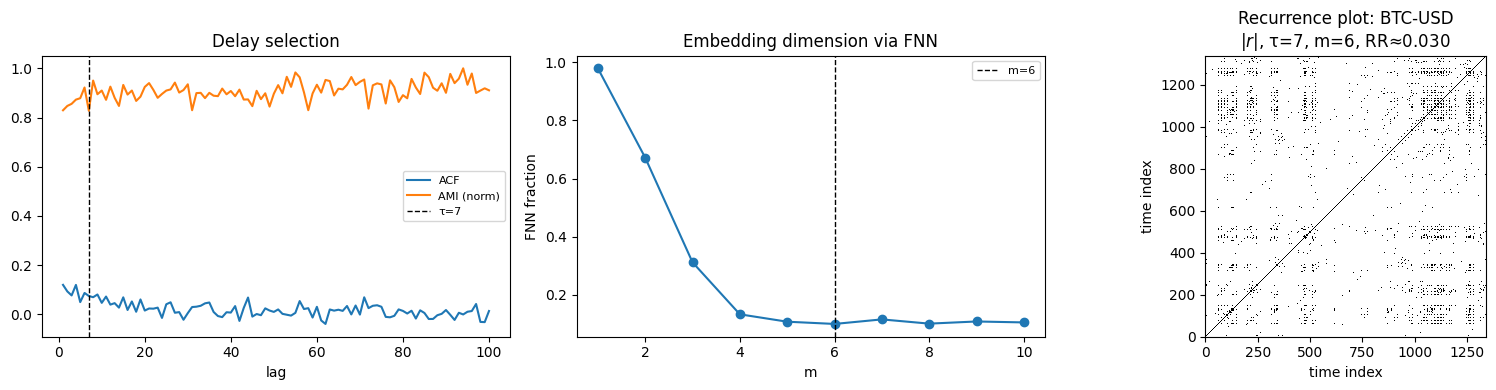

,Asset,N_used,tau,m,epsilon,RR_target,RR_achieved,DET(lmin=2),LAM(vmin=2)
0,BTC-USD,1341,7,6,1.607346,0.03,0.030001,0.113226,0.256984


In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Ensure plots render in-notebook (Cursor/VSCode kernels can default to non-inline)
try:
    get_ipython().run_line_magic("matplotlib", "inline")
except Exception:
    pass

from scipy.spatial.distance import pdist, squareform
from sklearn.metrics import mutual_info_score
from sklearn.neighbors import NearestNeighbors

# ==================================================
# Recurrence Plot (RP) + basic RQA on |returns|
#   - Uses the SAME data already loaded earlier in this notebook
#   - No EVT/tail refitting, no forecasting claims
# ==================================================

# ------------------------------
# User-tunable settings
# ------------------------------
RR_TARGET = 0.03   # recurrence rate target in [0.01, 0.05]
MAX_LAG = 100      # max lag for ACF/AMI
MAX_M = 10         # max embedding dimension to test in FNN
MAX_POINTS = 2000  # cap points to keep O(N^2) distance manageable
USE_VOL_PROXY = False
VOL_WINDOW = 20

# ------------------------------
# 0) Get returns from existing notebook objects
# ------------------------------

def get_returns_df():
    """Return a DataFrame of returns already computed in the notebook."""
    if "log_returns" in globals() and isinstance(log_returns, pd.DataFrame):
        return log_returns
    if "R" in globals() and isinstance(R, pd.DataFrame):
        return R
    if "r_df" in globals() and isinstance(r_df, pd.DataFrame):
        return r_df
    if "prices" in globals() and isinstance(prices, pd.DataFrame):
        pr = prices.replace([np.inf, -np.inf], np.nan).dropna(how="all")
        return np.log(pr / pr.shift(1)).dropna(how="all")

    raise RuntimeError(
        "No returns found in memory. Run the earlier cell that downloads data and computes `log_returns` (or defines `prices`)."
    )


returns_df = get_returns_df().replace([np.inf, -np.inf], np.nan).dropna(how="all")

# ------------------------------
# 1) Choose an asset with strong fat-tail behavior
# ------------------------------
if "summary" in globals() and isinstance(summary, pd.DataFrame) and {"Ticker", "GPD_xi"}.issubset(summary.columns):
    asset = summary.sort_values("GPD_xi", ascending=False).iloc[0]["Ticker"]
    if asset not in returns_df.columns:
        asset = returns_df.columns[0]
else:
    candidates = [c for c in ["BTC-USD", "^VIX", "ETH-USD", "TSLA"] if c in returns_df.columns]
    asset = candidates[0] if candidates else returns_df.columns[0]

# ------------------------------
# 2) Build signal: x_t = |r_t| (or optional vol proxy)
# ------------------------------
r = returns_df[asset].dropna()
x = np.abs(r.values)

if USE_VOL_PROXY:
    x = (
        pd.Series(x, index=r.index)
        .rolling(VOL_WINDOW)
        .mean()
        .dropna()
        .values
    )

# Robust standardization (median/MAD) for distance computations under fat tails
med = np.median(x)
mad = np.median(np.abs(x - med))
scale = (1.4826 * mad) if mad > 0 else (x.std() + 1e-12)
xz = (x - med) / (scale + 1e-12)

# ------------------------------
# 3) Delay τ via AMI (+ ACF for context)
# ------------------------------

def _first_local_minimum(y):
    for i in range(1, len(y) - 1):
        if y[i] < y[i - 1] and y[i] < y[i + 1]:
            return i
    return None


def acf(x, max_lag=MAX_LAG):
    x = np.asarray(x) - np.mean(x)
    denom = np.dot(x, x) + 1e-12
    return np.asarray([np.dot(x[:-lag], x[lag:]) / denom for lag in range(1, max_lag + 1)])


def delay_by_ami(x, max_lag=MAX_LAG, n_bins=32):
    x = np.asarray(x)

    # Quantile binning is stable under heavy tails
    edges = np.unique(np.quantile(x, np.linspace(0, 1, n_bins + 1)))
    if len(edges) < 5:
        return 1, None

    xb = np.digitize(x, edges[1:-1], right=True)
    mi = np.asarray([mutual_info_score(xb[:-lag], xb[lag:]) for lag in range(1, max_lag + 1)])

    idx = _first_local_minimum(mi)
    tau = (idx + 1) if idx is not None else 1
    return int(np.clip(tau, 1, max_lag)), mi


acf_vals = acf(xz, max_lag=MAX_LAG)
tau, ami_vals = delay_by_ami(xz, max_lag=MAX_LAG, n_bins=32)

# ------------------------------
# 4) Embedding dimension m via False Nearest Neighbors (FNN)
# ------------------------------

def embed_1d(x, m, tau):
    x = np.asarray(x)
    n = len(x) - (m - 1) * tau
    if n <= 10:
        raise ValueError("Time series too short for chosen (m, tau).")
    return np.column_stack([x[i : i + n] for i in range(0, m * tau, tau)])


def fnn_fraction(x, tau, max_m=MAX_M, rtol=10.0, atol=2.0):
    """FNN fraction computed on the common (m vs m+1) window length."""
    x = np.asarray(x)
    fracs = []
    sigma = x.std() + 1e-12

    for m in range(1, max_m + 1):
        n_common = len(x) - m * tau
        if n_common <= 10:
            fracs.append(np.nan)
            continue

        Xm = embed_1d(x, m, tau)[:n_common]
        Xm1 = embed_1d(x, m + 1, tau)  # exactly n_common rows

        nn = NearestNeighbors(n_neighbors=2).fit(Xm)
        dists, inds = nn.kneighbors(Xm, return_distance=True)

        d = dists[:, 1] + 1e-12
        j = inds[:, 1]
        delta = np.abs(Xm1[:, -1] - Xm1[j, -1])

        fracs.append(((delta / d > rtol) | (delta / sigma > atol)).mean())

    return np.asarray(fracs)


fnn_fracs = fnn_fraction(xz, tau=tau, max_m=MAX_M)
m_candidates = np.where(np.isfinite(fnn_fracs) & (fnn_fracs < 0.02))[0]
m = int(m_candidates[0] + 1) if len(m_candidates) else int(np.nanargmin(fnn_fracs) + 1)

# ------------------------------
# 5) Recurrence matrix: choose ε to hit low RR
# ------------------------------

def epsilon_for_target_rr(dist, rr_target=RR_TARGET, iters=35):
    n = dist.shape[0]
    off = dist[np.triu_indices(n, 1)]
    lo, hi = float(off.min()), float(off.max())

    for _ in range(iters):
        mid = 0.5 * (lo + hi)
        rr = float(np.mean(off <= mid))
        if rr < rr_target:
            lo = mid
        else:
            hi = mid

    eps = hi
    rr = float(np.mean(off <= eps))
    return eps, rr


X = embed_1d(xz, m=m, tau=tau)
if X.shape[0] > MAX_POINTS:
    X = X[-MAX_POINTS:]

D = squareform(pdist(X, metric="euclidean"))
eps, rr_achieved = epsilon_for_target_rr(D, rr_target=RR_TARGET)
R = (D <= eps)
np.fill_diagonal(R, True)

# ------------------------------
# 6) Basic RQA: RR, DET, LAM
# ------------------------------

def _run_lengths(b):
    out, run = [], 0
    for v in b:
        if v:
            run += 1
        elif run:
            out.append(run)
            run = 0
    if run:
        out.append(run)
    return out


def rqa_measures(R, lmin=2, vmin=2):
    R0 = R.copy()
    np.fill_diagonal(R0, False)

    n = R0.shape[0]
    total = int(R0.sum())
    RR = total / (n * (n - 1)) if n > 1 else np.nan
    if total == 0:
        return {"RR": RR, "DET": np.nan, "LAM": np.nan}

    diag_points = 0
    for k in range(-(n - 1), n):
        if k == 0:
            continue
        for L in _run_lengths(np.diagonal(R0, offset=k)):
            if L >= lmin:
                diag_points += L

    vert_points = 0
    for j in range(n):
        for L in _run_lengths(R0[:, j]):
            if L >= vmin:
                vert_points += L

    return {"RR": RR, "DET": diag_points / total, "LAM": vert_points / total}


rqa = rqa_measures(R, lmin=2, vmin=2)

# ------------------------------
# 7) Plots + outputs
# ------------------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].plot(np.arange(1, MAX_LAG + 1), acf_vals, label="ACF")
if ami_vals is not None:
    axes[0].plot(np.arange(1, MAX_LAG + 1), ami_vals / (ami_vals.max() + 1e-12), label="AMI (norm)")
axes[0].axvline(tau, color="k", ls="--", lw=1, label=f"τ={tau}")
axes[0].set_title("Delay selection")
axes[0].set_xlabel("lag")
axes[0].legend(fontsize=8)

axes[1].plot(np.arange(1, MAX_M + 1), fnn_fracs, marker="o")
axes[1].axvline(m, color="k", ls="--", lw=1, label=f"m={m}")
axes[1].set_title("Embedding dimension via FNN")
axes[1].set_xlabel("m")
axes[1].set_ylabel("FNN fraction")
axes[1].legend(fontsize=8)

axes[2].imshow(R.astype(int), cmap="binary", origin="lower", interpolation="none")
axes[2].set_title(f"Recurrence plot: {asset}\n$|r|$, τ={tau}, m={m}, RR≈{rr_achieved:.3f}")
axes[2].set_xlabel("time index")
axes[2].set_ylabel("time index")

plt.tight_layout()
plt.show()

rqa_out = pd.DataFrame([
    {
        "Asset": asset,
        "N_used": int(R.shape[0]),
        "tau": int(tau),
        "m": int(m),
        "epsilon": float(eps),
        "RR_target": float(RR_TARGET),
        "RR_achieved": float(rr_achieved),
        "DET(lmin=2)": float(rqa["DET"]),
        "LAM(vmin=2)": float(rqa["LAM"]),
    }
])

rqa_out


## RP/RQA comparison across regimes: stable equity vs volatile equity vs crypto

We now repeat the **same recurrence-plot + RQA pipeline** for three assets:

- **Stable equity**: HSBC (typically lower volatility, fewer large jumps)
- **Volatile equity**: NFLX (equity with larger swings / episodic bursts)
- **Crypto**: BTC (BTC-USD; typically the most intermittent)

### What to compare (and what not to claim)
- We **do not** use recurrence plots as prediction tools.
- We **do not** reduce results to “BTC is chaotic”. Instead, we compare *structure* in the volatility/magnitude dynamics.

Because $\epsilon$ is chosen to target a low recurrence rate (RR ≈ 1–5%), RR is mainly a **sanity check** that thresholding is comparable across assets. The informative differences show up in:

- **DET (determinism)**: recurrence points concentrated into diagonal line structure (repeated evolution patterns)
- **LAM (laminarity)**: recurrence points concentrated into vertical structures (persistence / volatility clustering)
- **Visual RP texture**: broken diagonals, vertical blocks, and white gaps (intermittency / extreme-event dominance)

### Why this is powerful (beyond “BTC is chaotic”)
This comparison replaces a vague label with **specific dynamical signatures**:

- **Stable equity**: typically more homogeneous texture and fewer large white gaps (rarer excursions to extreme states).
- **Volatile equity**: more visible regime switching (broken diagonals) and persistence blocks.
- **Crypto**: often the strongest intermittency signature (large gaps + dense vertical blocks), consistent with heavy tails and clustering.

Interpreted alongside your EVT/power-law results, this supports a coherent story: fat tails and truncation are not just distributional facts—they reflect **time-organized excursions and persistence** in the underlying volatility/magnitude dynamics.


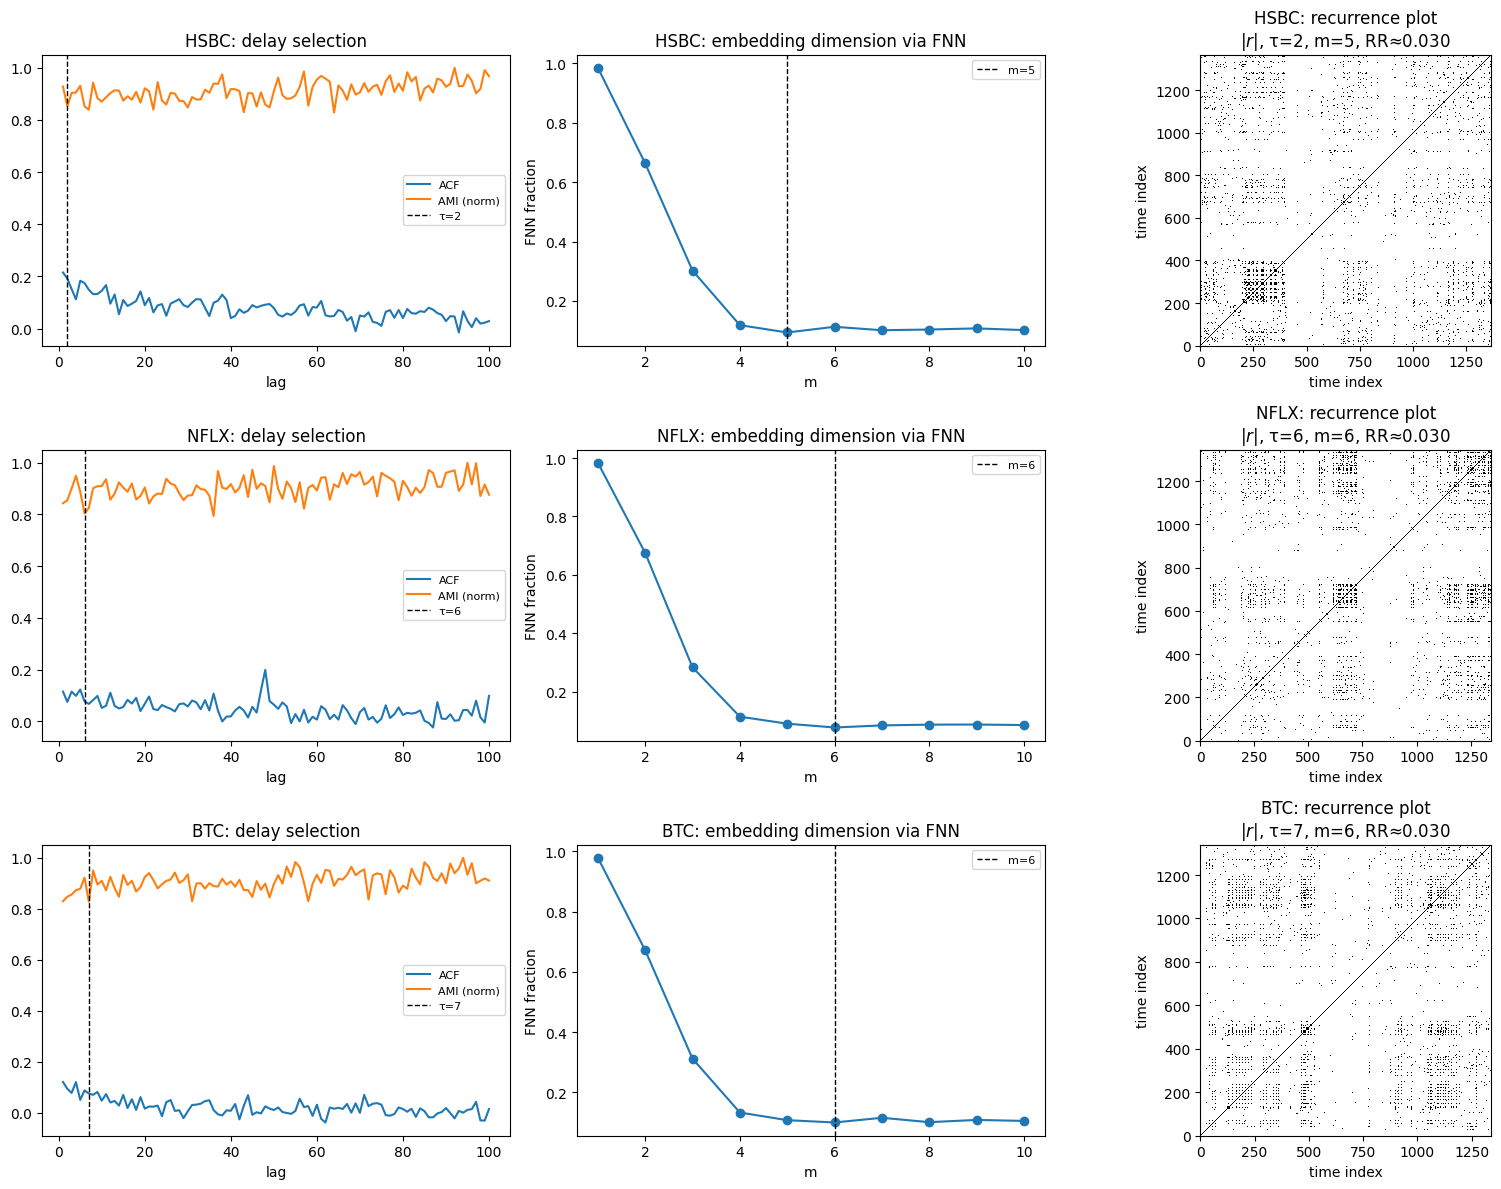

,Ticker,N_used,tau,m,RR_target,RR,DET,LAM
Asset,,,,,,,,
HSBC,HSBC,1368,2,5,0.03,0.030000,0.085665,0.178265
NFLX,NFLX,1346,6,6,0.03,0.030000,0.116622,0.202405
BTC,BTC-USD,1341,7,6,0.03,0.030001,0.113226,0.256984


In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==================================================
# Repeat the SAME RP + RQA pipeline for HSBC / NFLX / BTC
#   Requires: the previous RP/RQA cell has been run (it defines helper fns)
# ==================================================

# Guard: ensure we can reuse the same data source
if "get_returns_df" not in globals():
    raise RuntimeError("Run the previous RP/RQA cell first (it defines `get_returns_df` and helper functions).")

returns_df = get_returns_df().replace([np.inf, -np.inf], np.nan).dropna(how="all")

# Map user-friendly BTC -> Yahoo ticker used earlier
assets = {
    "HSBC": "HSBC",
    "NFLX": "NFLX",
    "BTC": "BTC-USD",
}

missing = [name for name, col in assets.items() if col not in returns_df.columns]
if missing:
    raise RuntimeError(
        "Missing assets in returns data: "
        + ", ".join(missing)
        + ". Make sure your earlier download cell included these tickers and `log_returns` was computed."
    )

# Reuse the same settings from the single-asset RP cell
RR_TARGET = float(globals().get("RR_TARGET", 0.03))
MAX_LAG = int(globals().get("MAX_LAG", 100))
MAX_M = int(globals().get("MAX_M", 10))
MAX_POINTS = int(globals().get("MAX_POINTS", 2000))
USE_VOL_PROXY = bool(globals().get("USE_VOL_PROXY", False))
VOL_WINDOW = int(globals().get("VOL_WINDOW", 20))

# Helper wrappers (use the exact same logic as the single-asset cell)
acf = globals()["acf"]
delay_by_ami = globals()["delay_by_ami"]
embed_1d = globals()["embed_1d"]
fnn_fraction = globals()["fnn_fraction"]
epsilon_for_target_rr = globals()["epsilon_for_target_rr"]
rqa_measures = globals()["rqa_measures"]


def compute_rp_rqa_for_asset(returns_df: pd.DataFrame, asset_col: str):
    r = returns_df[asset_col].dropna()
    x = np.abs(r.values)

    if USE_VOL_PROXY:
        x = (
            pd.Series(x, index=r.index)
            .rolling(VOL_WINDOW)
            .mean()
            .dropna()
            .values
        )

    med = np.median(x)
    mad = np.median(np.abs(x - med))
    scale = (1.4826 * mad) if mad > 0 else (x.std() + 1e-12)
    xz = (x - med) / (scale + 1e-12)

    acf_vals = acf(xz, max_lag=MAX_LAG)
    tau, ami_vals = delay_by_ami(xz, max_lag=MAX_LAG, n_bins=32)

    fnn_fracs = fnn_fraction(xz, tau=tau, max_m=MAX_M)
    m_candidates = np.where(np.isfinite(fnn_fracs) & (fnn_fracs < 0.02))[0]
    m = int(m_candidates[0] + 1) if len(m_candidates) else int(np.nanargmin(fnn_fracs) + 1)

    X = embed_1d(xz, m=m, tau=tau)
    if X.shape[0] > MAX_POINTS:
        X = X[-MAX_POINTS:]

    # pairwise distances + threshold for target RR
    from scipy.spatial.distance import pdist, squareform

    D = squareform(pdist(X, metric="euclidean"))
    eps, rr_achieved = epsilon_for_target_rr(D, rr_target=RR_TARGET)

    R = (D <= eps)
    np.fill_diagonal(R, True)

    rqa = rqa_measures(R, lmin=2, vmin=2)

    return {
        "asset_col": asset_col,
        "N_used": int(R.shape[0]),
        "tau": int(tau),
        "m": int(m),
        "epsilon": float(eps),
        "RR_target": float(RR_TARGET),
        "RR_achieved": float(rr_achieved),
        "DET": float(rqa["DET"]),
        "LAM": float(rqa["LAM"]),
        "acf_vals": acf_vals,
        "ami_vals": ami_vals,
        "fnn_fracs": fnn_fracs,
        "R": R,
    }


results = {name: compute_rp_rqa_for_asset(returns_df, col) for name, col in assets.items()}

# ------------------------------
# Plot: 3 rows (assets) x 3 columns (ACF/AMI, FNN, RP)
# ------------------------------
fig, axes = plt.subplots(len(assets), 3, figsize=(16, 4 * len(assets)))
if len(assets) == 1:
    axes = np.array([axes])

for row, (name, res) in enumerate(results.items()):
    # ACF + AMI
    ax = axes[row, 0]
    ax.plot(np.arange(1, MAX_LAG + 1), res["acf_vals"], label="ACF")
    if res["ami_vals"] is not None:
        ax.plot(
            np.arange(1, MAX_LAG + 1),
            res["ami_vals"] / (res["ami_vals"].max() + 1e-12),
            label="AMI (norm)",
        )
    ax.axvline(res["tau"], color="k", ls="--", lw=1, label=f"τ={res['tau']}")
    ax.set_title(f"{name}: delay selection")
    ax.set_xlabel("lag")
    ax.legend(fontsize=8)

    # FNN
    ax = axes[row, 1]
    ax.plot(np.arange(1, MAX_M + 1), res["fnn_fracs"], marker="o")
    ax.axvline(res["m"], color="k", ls="--", lw=1, label=f"m={res['m']}")
    ax.set_title(f"{name}: embedding dimension via FNN")
    ax.set_xlabel("m")
    ax.set_ylabel("FNN fraction")
    ax.legend(fontsize=8)

    # RP
    ax = axes[row, 2]
    ax.imshow(res["R"].astype(int), cmap="binary", origin="lower", interpolation="none")
    ax.set_title(
        f"{name}: recurrence plot\n"
        f"$|r|$, τ={res['tau']}, m={res['m']}, RR≈{res['RR_achieved']:.3f}"
    )
    ax.set_xlabel("time index")
    ax.set_ylabel("time index")

plt.tight_layout()
plt.show()

# ------------------------------
# Comparison table
# ------------------------------
compare = pd.DataFrame([
    {
        "Asset": name,
        "Ticker": res["asset_col"],
        "N_used": res["N_used"],
        "tau": res["tau"],
        "m": res["m"],
        "RR_target": res["RR_target"],
        "RR": res["RR_achieved"],
        "DET": res["DET"],
        "LAM": res["LAM"],
    }
    for name, res in results.items()
]).set_index("Asset")

compare


CHAOS EVIDENCE & STATISTICAL RESULTS COLLECTOR



C:\Users\VEDANT\AppData\Local\Temp\ipykernel_7692\140628246.py:192: FutureWarning: YF.download() has changed argument auto_adjust default to True
  prices = yf.download(tickers, start=start, end=end, progress=False)["Close"]



(i) CHAOS EVIDENCE - LYAPUNOV & HURST EXPONENTS

Analyzing AAPL...
  Classification: MODERATELY CHAOTIC (Score: 4)
    • λ=0.2115 > 0.1 (HIGHLY CHAOTIC)
    • H=0.5747 > 0.5 (PERSISTENT)
    • DET=0.3511 (MODERATE)
    • ENTR=1.3761 (MODERATE COMPLEXITY)
  Computing Generalized Pareto Distribution...
    GPD Shape (ξ): 0.0124 - HEAVY TAIL
    GPD Scale (β): 0.014232
    Threshold (u): 0.019351
    VaR(95%): 0.029300
    ES(95%): 0.043835
    KS test p-value: 0.9443 (Good fit)

Analyzing MSFT...
  Classification: MODERATELY CHAOTIC (Score: 3)
    • λ=0.2079 > 0.1 (HIGHLY CHAOTIC)
    • H=0.4136 < 0.5 (MEAN-REVERTING)
    • DET=0.3599 (MODERATE)
    • ENTR=1.3908 (MODERATE COMPLEXITY)
  Computing Generalized Pareto Distribution...
    GPD Shape (ξ): -0.0097 - LIGHT TAIL
    GPD Scale (β): 0.012833
    Threshold (u): 0.019782
    VaR(95%): 0.028684
    ES(95%): 0.041307
    KS test p-value: 0.7722 (Good fit)

Analyzing TSLA...
  Classification: HIGHLY CHAOTIC (Score: 5)
    • λ=0.2113 > 

C:\Users\VEDANT\AppData\Local\Temp\ipykernel_7692\140628246.py:575: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\VEDANT\AppData\Local\Temp\ipykernel_7692\140628246.py:575: UserWarning: Glyph 8320 (\N{SUBSCRIPT ZERO}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\VEDANT\AppData\Local\Temp\ipykernel_7692\140628246.py:576: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Arial.
  plt.savefig('gpd_analysis_results.png', dpi=300, bbox_inches='tight')
C:\Users\VEDANT\AppData\Local\Temp\ipykernel_7692\140628246.py:576: UserWarning: Glyph 8320 (\N{SUBSCRIPT ZERO}) missing from font(s) Arial.
  plt.savefig('gpd_analysis_results.png', dpi=300, bbox_inches='tight')


✓ Saved: gpd_analysis_results.png
✓ Saved: statistical_results_summary.png
✓ Saved: chaos_gpd_relationship.png
✓ Saved: lyapunov_hurst_distributions.png
✓ Saved: gpd_tail_analysis.png


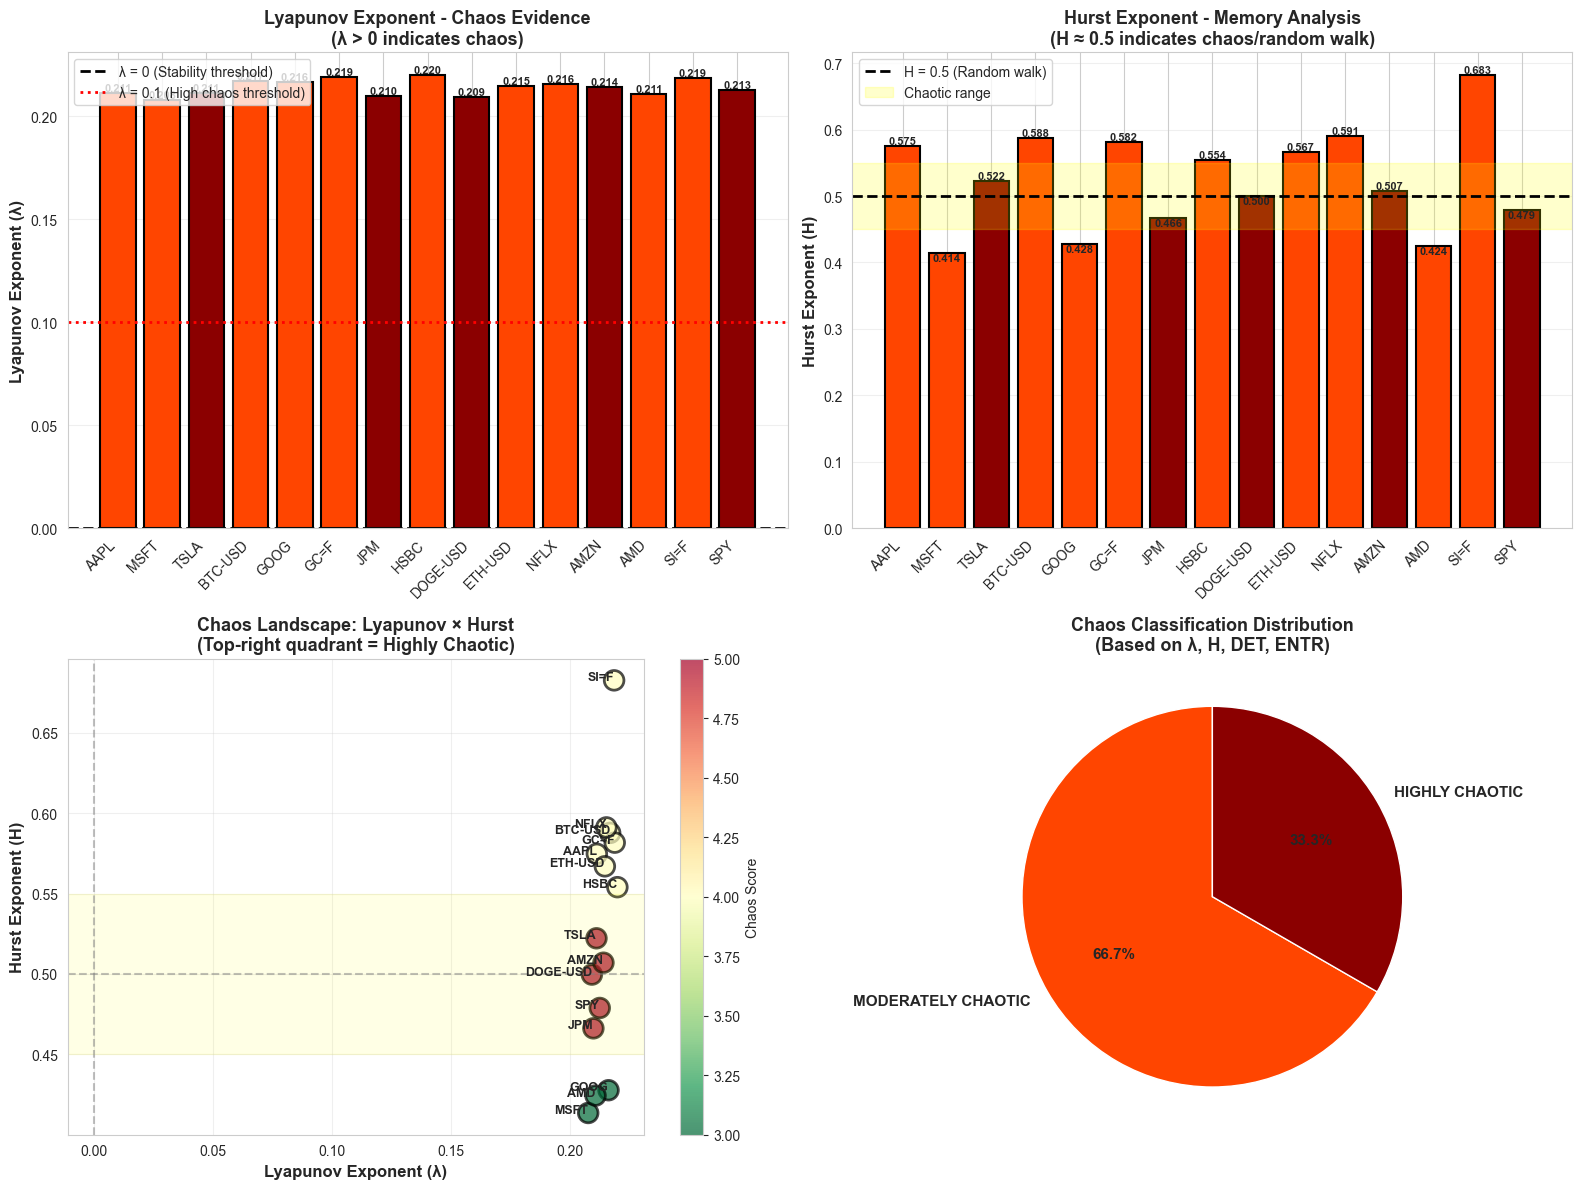

C:\Users\VEDANT\AppData\Roaming\Python\Python310\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\VEDANT\AppData\Roaming\Python\Python310\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8320 (\N{SUBSCRIPT ZERO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


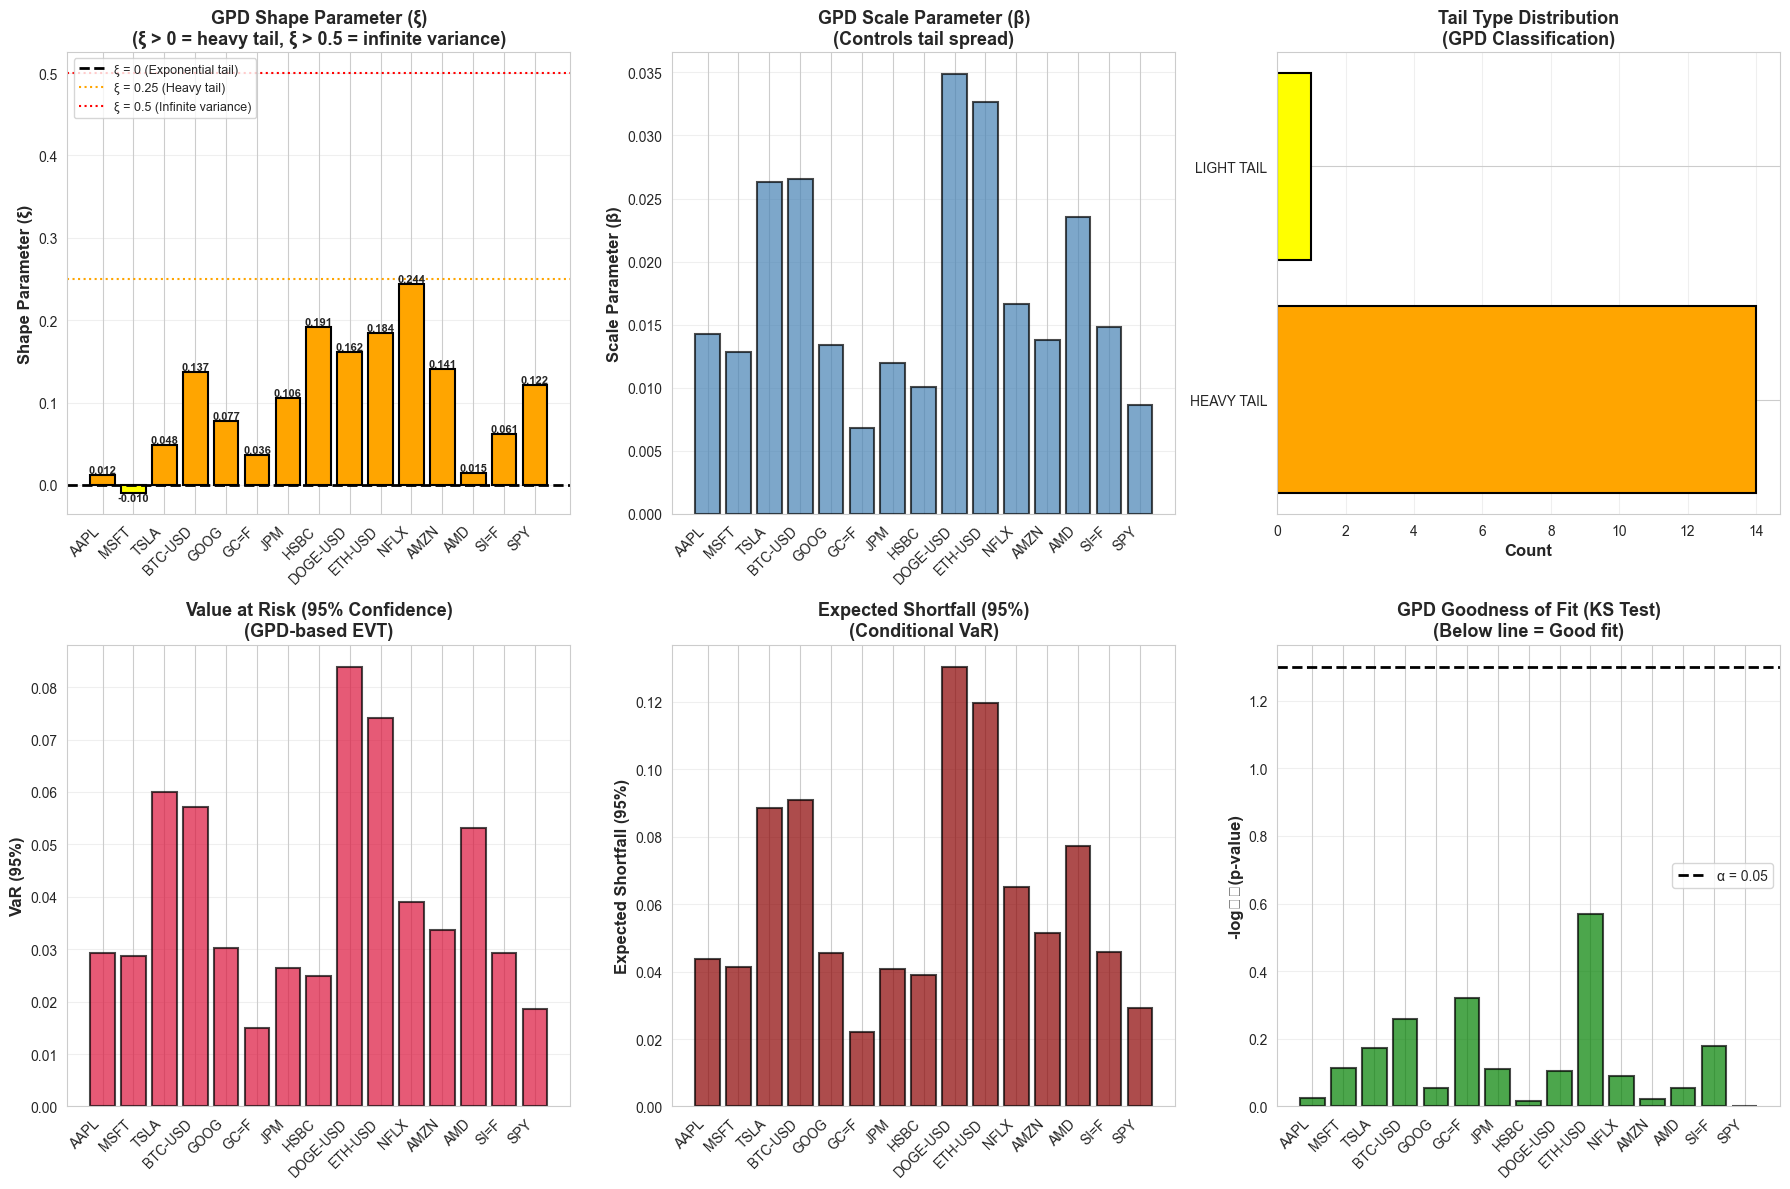

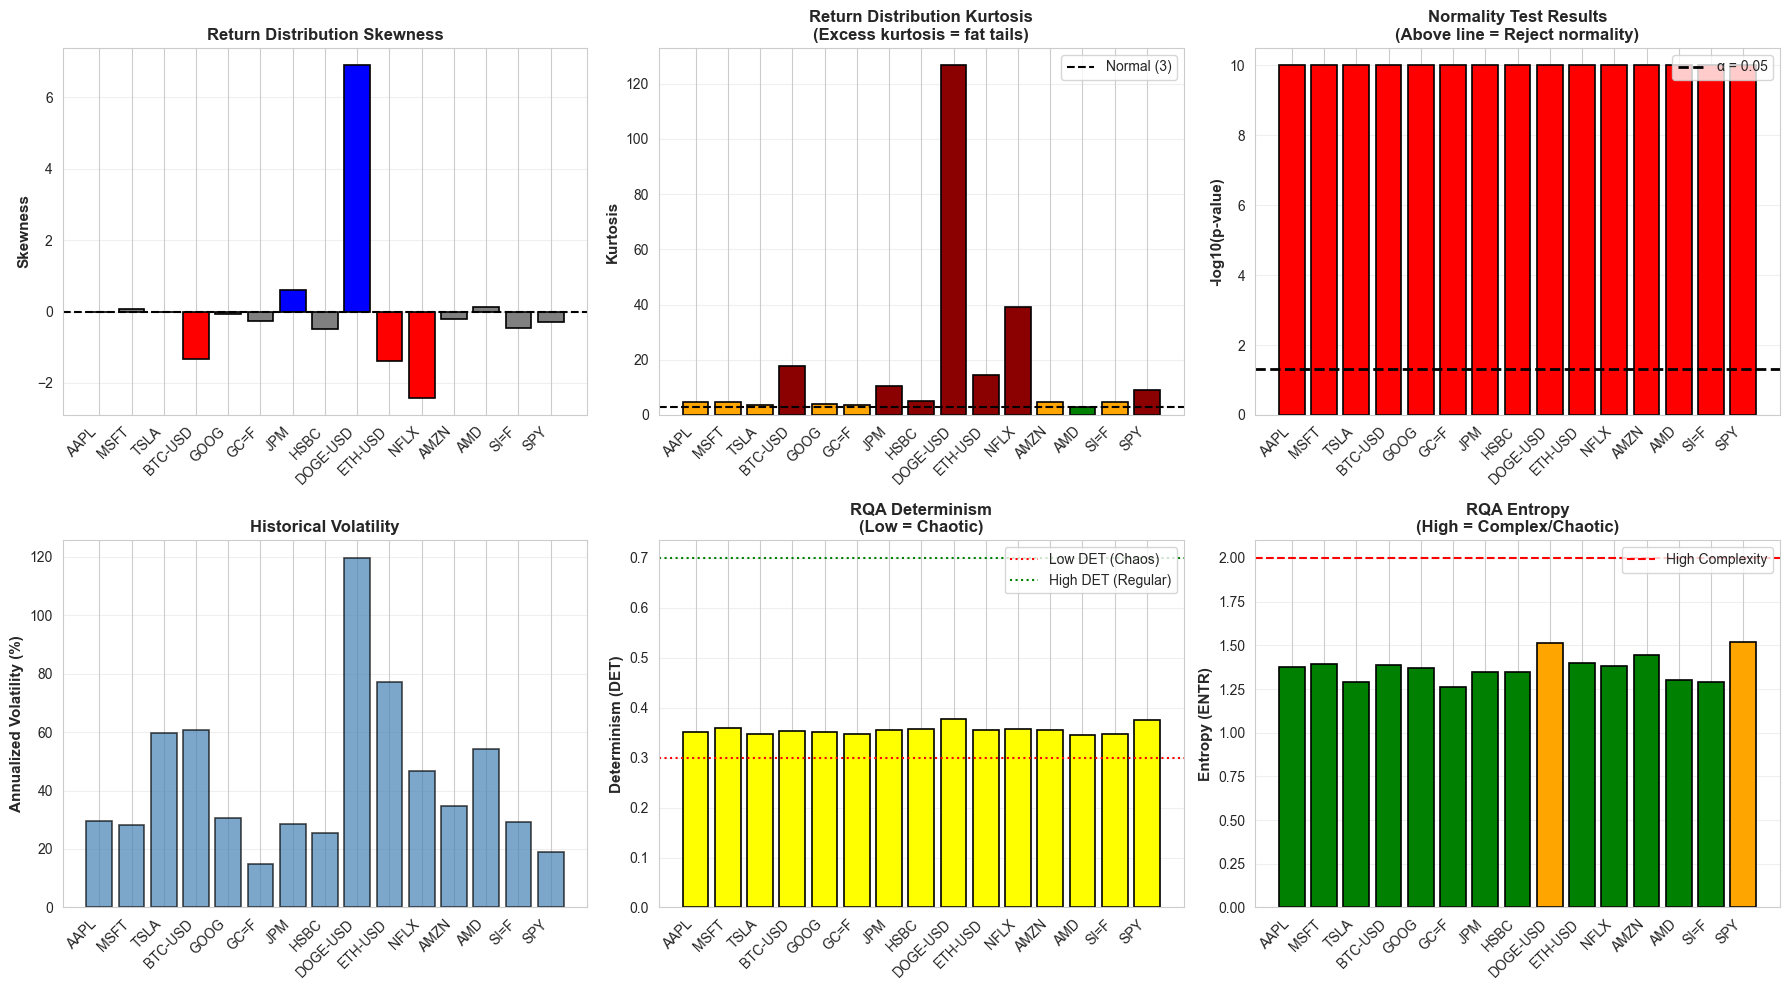

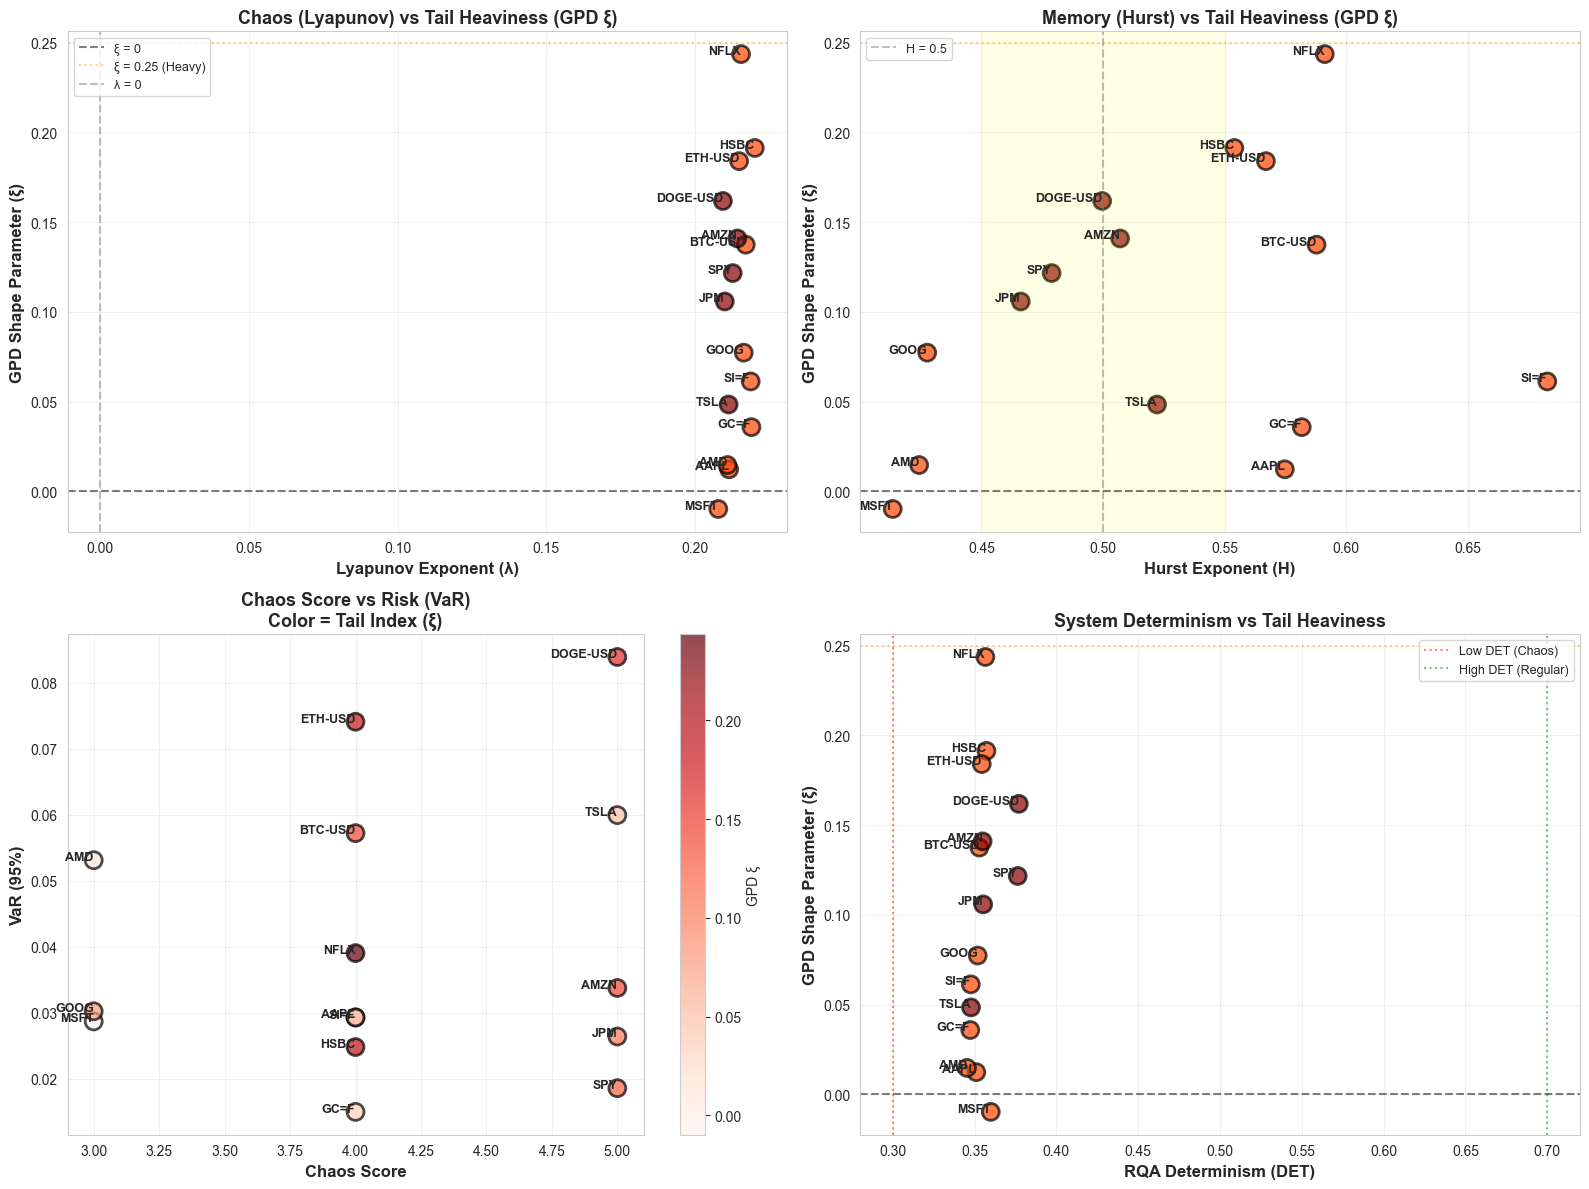

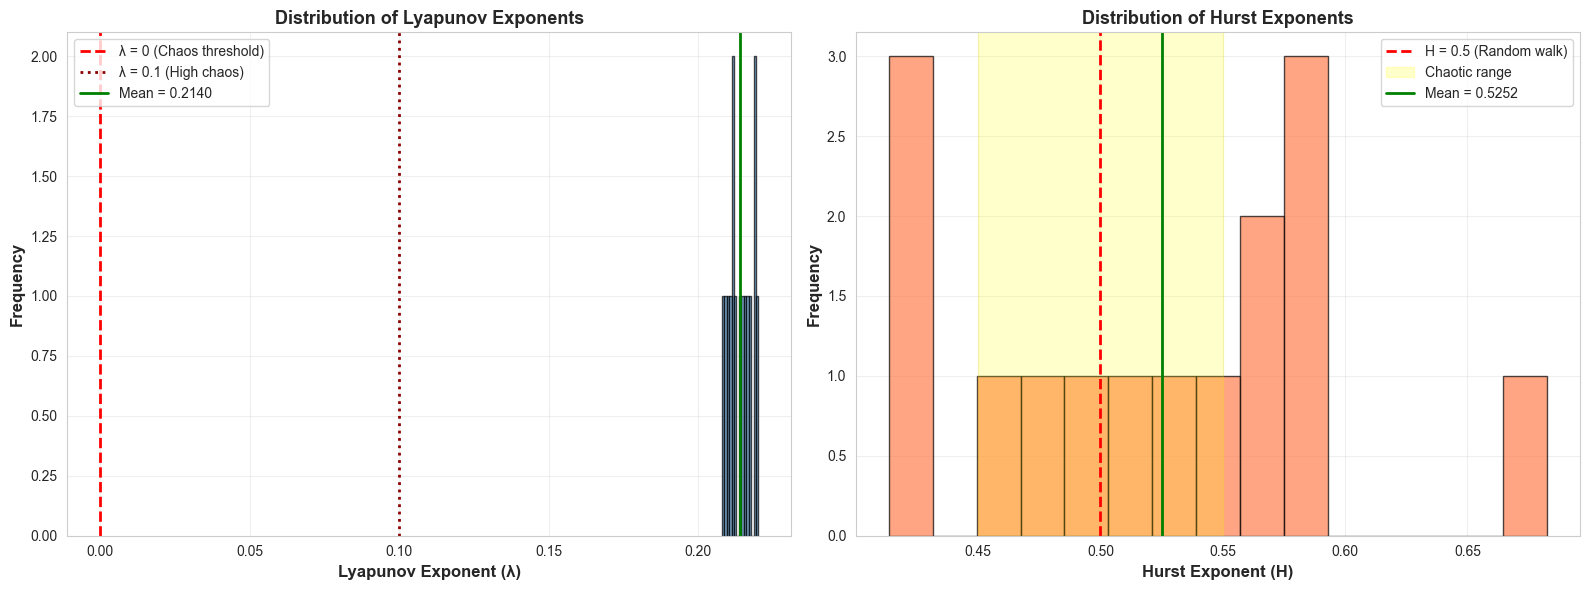

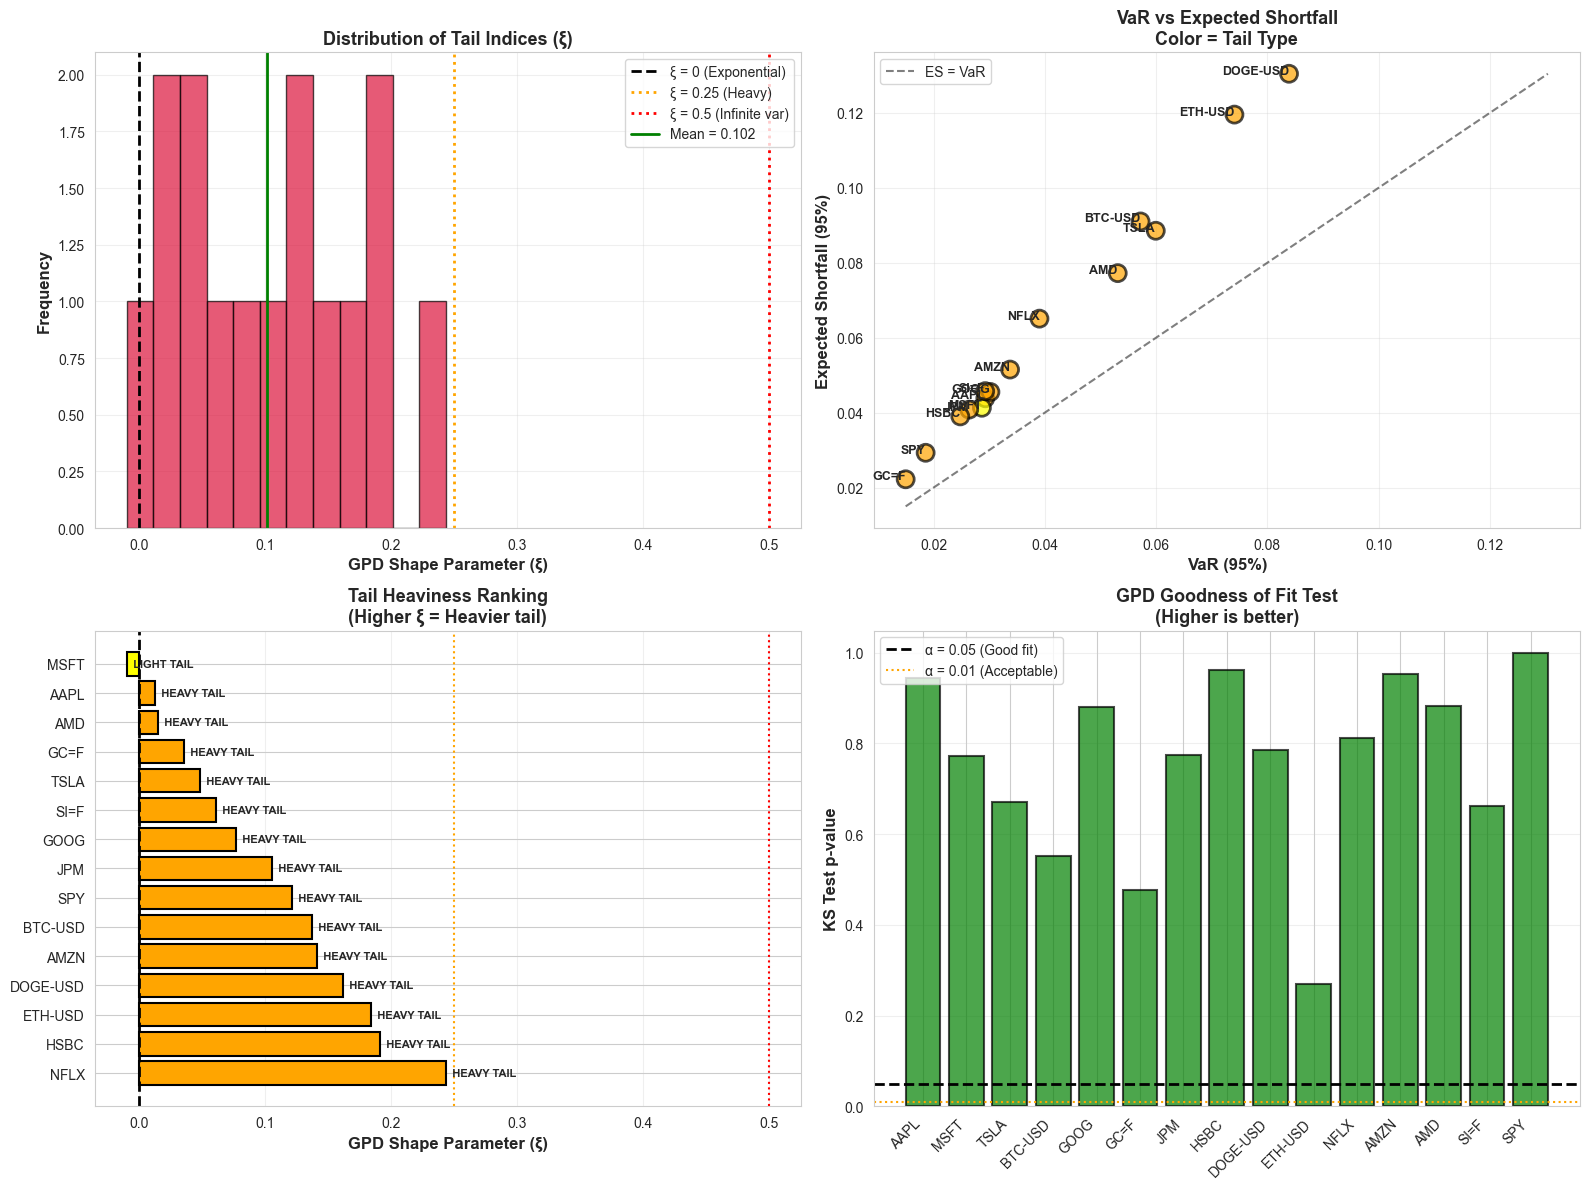


EXPORTING RESULTS TO CSV
✓ Saved: chaos_statistical_gpd_results.csv
✓ Saved: chaos_evidence_only.csv
✓ Saved: gpd_results_only.csv

ANALYSIS COMPLETE!

Generated Files:
  1. chaos_evidence_lyapunov_hurst.png - Chaos metrics visualization
  2. gpd_analysis_results.png - GPD parameters and risk measures
  3. statistical_results_summary.png - Statistical analysis
  4. chaos_gpd_relationship.png - Chaos vs tail heaviness
  5. lyapunov_hurst_distributions.png - Distribution analysis
  6. gpd_tail_analysis.png - Detailed tail analysis
  7. chaos_statistical_gpd_results.csv - Complete results
  8. chaos_evidence_only.csv - Pure chaos metrics
  9. gpd_results_only.csv - Pure GPD results
